# Interconnect · 01 — Auditoría de datos, contratos y perfiles de abandono

**Proyecto:** Predicción de abandono de clientes · TripleTen  
**Documento:** notebook de investigación independiente · versión de cierre documentado  
**Datos:** cuatro CSV locales en `data/raw/`; foco analítico en `contract.csv`  
**Marco:** CRISP-DM · comprensión de datos y experimentos retrospectivos

> **Objetivo:** entender la estructura de las fuentes y las diferencias contractuales y económicas de quienes cancelaron, terminando con una **segmentación no supervisada exclusivamente descriptiva** de los desertores.

**Secuencia preservada:** **A.** auditoría individual de cuatro tablas → **B.** investigación retrospectiva de contratos y cargos → **C.** primer clustering K-Means de desertores → **D.** conclusiones, límites y decisiones. Se mantiene el orden de todas las celdas de código y sus gráficos.

**Lectura de evidencias:** las cifras de las conclusiones se contrastaron con las **salidas guardadas del notebook recibido**. Las salidas se conservan para lectura y trazabilidad, pero los CSV no acompañan esta copia: la verificación definitiva de ejecución corresponde al entorno local en VS Code. En caso de divergencia, prevalecen los cálculos recién ejecutados con las fuentes verificadas.

**Reglas:** no modificar CSV, no interpretar asociación como causalidad, no confundir duración final con antigüedad disponible para predicción y no interpretar los clusters como probabilidades de abandono.

**Convención visual existente:** verde petróleo = sin baja registrada; terracota = con baja registrada; azul pizarra y colores complementarios = referencias y clusters. Los estilos y el código de las figuras se preservan exactamente como fueron ejecutados.

## A. Auditoría individual de las fuentes · comprensión de datos

### A1. Entorno, bibliotecas y estilo visual

**Pregunta:** ¿dónde se ejecuta el notebook y dónde están los CSV? Se inicializan bibliotecas y una paleta común para los gráficos. La carga utiliza rutas relativas, sin tocar los archivos originales.

**Control metodológico:** esta sección examina las cuatro tablas **por separado**. No realiza joins, imputaciones ni construcción de variables para ML.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter

# Paleta analítica única. No se utilizan estilos dependientes de seaborn.
COLOR = {
    "activo": "#23877F",    # contratos sin baja
    "baja": "#D16E46",      # baja registrada / tasa de abandono
    "tinta": "#263746",     # títulos y ejes
    "muted": "#61737F",     # texto secundario
    "grid": "#DCE5EA",      # cuadrícula discreta
    "referencia": "#547B91",
    "paperless_no": "#9DAEB8",
    "paperless_yes": "#547B91",
}
COLORES_TIPO = {
    "Month-to-month": "#547B91",
    "One year": "#23877F",
    "Two year": "#B08C61",
}

plt.rcParams.update({
    "figure.figsize": (8, 4),
    "figure.dpi": 120,
    "savefig.dpi": 160,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": COLOR["grid"],
    "axes.labelcolor": COLOR["tinta"],
    "axes.titlecolor": COLOR["tinta"],
    "axes.titlesize": 12,
    "axes.titleweight": "semibold",
    "axes.labelsize": 10,
    "font.size": 10,
    "font.family": "DejaVu Sans",
    "text.color": COLOR["tinta"],
    "xtick.color": COLOR["muted"],
    "ytick.color": COLOR["muted"],
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.spines.left": False,
    "axes.spines.bottom": False,
    "legend.frameon": False,
})

PCT = FuncFormatter(lambda x, pos: f"{x:.0f}%")


def preparar_eje(ax, horizontal=False):
    """Aplicar el mismo tratamiento visual ligero a gráficos comparativos."""
    ax.set_axisbelow(True)
    ax.grid(axis="x" if horizontal else "y", color=COLOR["grid"], linewidth=0.8)
    ax.tick_params(length=0)


print("Pandas:", pd.__version__)
print("Matplotlib:", plt.matplotlib.__version__)
print("Directorio de ejecución:", Path.cwd())

Pandas: 2.3.3
Matplotlib: 3.11.1
Directorio de ejecución: e:\data tree\data science\tripleten bootcamp\sprint 19 proyecto final\interconnect-churn-prediction\notebooks


In [2]:
# VS Code puede ejecutar el notebook desde la raíz o desde notebooks/.
HERE = Path.cwd().resolve()
PROJECT_ROOT = HERE.parent if HERE.name.lower() == "notebooks" else HERE
DATA_DIR = PROJECT_ROOT / "data" / "raw"

if not DATA_DIR.is_dir():
    raise FileNotFoundError(
        f"No se encontró {DATA_DIR}. Ejecuta el notebook desde la raíz "
        "del proyecto o desde notebooks/ y verifica data/raw/."
    )

print("Raíz:", PROJECT_ROOT)
print("Datos:", DATA_DIR)

Raíz: E:\data tree\data science\tripleten bootcamp\sprint 19 proyecto final\interconnect-churn-prediction
Datos: E:\data tree\data science\tripleten bootcamp\sprint 19 proyecto final\interconnect-churn-prediction\data\raw


### A2. Inventario y carga sin alteraciones

**Pregunta:** ¿están presentes `contract.csv`, `internet.csv`, `personal.csv` y `phone.csv`? Primero se comprueba el inventario; después se leen los cuatro archivos.

**Criterio de salida:** cuatro DataFrames disponibles y dimensiones contrastables; esto no implica aún que todos sus identificadores coincidan.

In [3]:
FILE_NAMES = ["contract.csv", "internet.csv", "personal.csv", "phone.csv"]

inventario = pd.DataFrame({
    "archivo": FILE_NAMES,
    "existe": [(DATA_DIR / name).is_file() for name in FILE_NAMES],
    "tamaño_MB": [
        round((DATA_DIR / name).stat().st_size / (1024 ** 2), 3)
        if (DATA_DIR / name).is_file() else None
        for name in FILE_NAMES
    ],
})
display(inventario)

faltantes = inventario.loc[~inventario["existe"], "archivo"].tolist()
if faltantes:
    raise FileNotFoundError(f"Faltan archivos en data/raw/: {faltantes}")

,archivo,existe,tamaño_MB
0,contract.csv,True,0.521
1,internet.csv,True,0.211
2,personal.csv,True,0.173
3,phone.csv,True,0.088


In [4]:
# Lectura sin convertir fechas, crear objetivos ni modificar los originales.
contract = pd.read_csv(DATA_DIR / "contract.csv")
internet = pd.read_csv(DATA_DIR / "internet.csv")
personal = pd.read_csv(DATA_DIR / "personal.csv")
phone = pd.read_csv(DATA_DIR / "phone.csv")

datasets = {
    "contract": contract,
    "internet": internet,
    "personal": personal,
    "phone": phone,
}

resumen_dimensiones = pd.DataFrame(
    [(nombre, len(df), df.shape[1]) for nombre, df in datasets.items()],
    columns=["tabla", "filas", "columnas"],
).set_index("tabla")
display(resumen_dimensiones)

,filas,columnas
tabla,,
contract,7043,8
internet,5517,8
personal,7043,5
phone,6361,2


### A3. Inspección estructural de las cuatro tablas

**Pregunta:** ¿cuántos registros y columnas tiene cada fuente? ¿Qué tipos, ausencias reconocidas por Pandas o duplicados de filas se observan?

Se reutiliza una función de auditoría para mantener la misma inspección en las cuatro tablas. Una fila duplicada y un `customerID` duplicado son problemas distintos; aquí solo se verifican inicialmente las filas completas.

In [5]:
def inspeccionar_tabla(nombre, df):
    """Mostrar estructura y calidad inicial sin modificar el DataFrame."""
    print(f"\n{'=' * 65}\n{nombre.upper()} · {df.shape[0]:,} filas × {df.shape[1]} columnas")
    print("Columnas:", df.columns.tolist())
    print("\nPrimeros registros:")
    display(df.head())
    print("Estructura y tipos:")
    df.info()
    print("\nNulos detectados:")
    display(df.isna().sum().to_frame("nulos"))
    print("Filas totalmente duplicadas:", df.duplicated().sum())

#### A3.1 · `contract.csv` — contratos y cargos

**Lectura esperada:** 7.043 registros, ocho campos; atención a `EndDate` (estado o fecha) y `TotalCharges` (texto antes de conversión).

In [6]:
inspeccionar_tabla("contract", contract)


CONTRACT · 7,043 filas × 8 columnas
Columnas: ['customerID', 'BeginDate', 'EndDate', 'Type', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges']

Primeros registros:


,customerID,BeginDate,EndDate,Type,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,7590-VHVEG,2020-01-01,No,Month-to-month,Yes,Electronic check,29.85,29.85
1,5575-GNVDE,2017-04-01,No,One year,No,Mailed check,56.95,1889.5
2,3668-QPYBK,2019-10-01,2019-12-01 00:00:00,Month-to-month,Yes,Mailed check,53.85,108.15
3,7795-CFOCW,2016-05-01,No,One year,No,Bank transfer (automatic),42.30,1840.75
4,9237-HQITU,2019-09-01,2019-11-01 00:00:00,Month-to-month,Yes,Electronic check,70.70,151.65


Estructura y tipos:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   BeginDate         7043 non-null   object 
 2   EndDate           7043 non-null   object 
 3   Type              7043 non-null   object 
 4   PaperlessBilling  7043 non-null   object 
 5   PaymentMethod     7043 non-null   object 
 6   MonthlyCharges    7043 non-null   float64
 7   TotalCharges      7043 non-null   object 
dtypes: float64(1), object(7)
memory usage: 440.3+ KB

Nulos detectados:


,nulos
customerID,0
BeginDate,0
EndDate,0
Type,0
PaperlessBilling,0
PaymentMethod,0
MonthlyCharges,0
TotalCharges,0


Filas totalmente duplicadas: 0


#### A3.2 · `internet.csv` — servicios de internet

**Lectura esperada:** 5.517 registros; inspección estructural únicamente. Los valores de cada servicio se estudiarán en un notebook posterior.

In [7]:
inspeccionar_tabla("internet", internet)


INTERNET · 5,517 filas × 8 columnas
Columnas: ['customerID', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']

Primeros registros:


,customerID,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies
0,7590-VHVEG,DSL,No,Yes,No,No,No,No
1,5575-GNVDE,DSL,Yes,No,Yes,No,No,No
2,3668-QPYBK,DSL,Yes,Yes,No,No,No,No
3,7795-CFOCW,DSL,Yes,No,Yes,Yes,No,No
4,9237-HQITU,Fiber optic,No,No,No,No,No,No


Estructura y tipos:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5517 entries, 0 to 5516
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   customerID        5517 non-null   object
 1   InternetService   5517 non-null   object
 2   OnlineSecurity    5517 non-null   object
 3   OnlineBackup      5517 non-null   object
 4   DeviceProtection  5517 non-null   object
 5   TechSupport       5517 non-null   object
 6   StreamingTV       5517 non-null   object
 7   StreamingMovies   5517 non-null   object
dtypes: object(8)
memory usage: 344.9+ KB

Nulos detectados:


,nulos
customerID,0
InternetService,0
OnlineSecurity,0
OnlineBackup,0
DeviceProtection,0
TechSupport,0
StreamingTV,0
StreamingMovies,0


Filas totalmente duplicadas: 0


#### A3.3 · `personal.csv` — atributos personales

**Lectura esperada:** 7.043 registros; aún no inferimos relaciones entre características personales y abandono.

In [8]:
inspeccionar_tabla("personal", personal)


PERSONAL · 7,043 filas × 5 columnas
Columnas: ['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents']

Primeros registros:


,customerID,gender,SeniorCitizen,Partner,Dependents
0,7590-VHVEG,Female,0,Yes,No
1,5575-GNVDE,Male,0,No,No
2,3668-QPYBK,Male,0,No,No
3,7795-CFOCW,Male,0,No,No
4,9237-HQITU,Female,0,No,No


Estructura y tipos:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   customerID     7043 non-null   object
 1   gender         7043 non-null   object
 2   SeniorCitizen  7043 non-null   int64 
 3   Partner        7043 non-null   object
 4   Dependents     7043 non-null   object
dtypes: int64(1), object(4)
memory usage: 275.2+ KB

Nulos detectados:


,nulos
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0


Filas totalmente duplicadas: 0


#### A3.4 · `phone.csv` — telefonía

**Lectura esperada:** 6.361 registros; una menor cantidad de filas puede representar cobertura de servicio, pero debe validarse al cruzar identificadores.

In [9]:
inspeccionar_tabla("phone", phone)


PHONE · 6,361 filas × 2 columnas
Columnas: ['customerID', 'MultipleLines']

Primeros registros:


,customerID,MultipleLines
0,5575-GNVDE,No
1,3668-QPYBK,No
2,9237-HQITU,No
3,9305-CDSKC,Yes
4,1452-KIOVK,Yes


Estructura y tipos:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6361 entries, 0 to 6360
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   customerID     6361 non-null   object
 1   MultipleLines  6361 non-null   object
dtypes: object(2)
memory usage: 99.5+ KB

Nulos detectados:


,nulos
customerID,0
MultipleLines,0


Filas totalmente duplicadas: 0


**Conclusión de A3:** los resultados guardados muestran **7.043 filas en `contract` y `personal`**, **5.517 en `internet`** y **6.361 en `phone`**, sin filas completas duplicadas en las salidas de inspección. Estas diferencias **no** demuestran errores de carga ni permiten concluir todavía cómo se relacionan los clientes entre fuentes.

### A4. Diccionario preliminar de `contract.csv`

**Pregunta:** ¿qué tipo de dato y cuántas categorías o valores distintos tiene cada campo? Una columna `object` no implica necesariamente una variable categórica: puede representar una fecha o un importe no parseado.

In [10]:
columnas_contract = pd.DataFrame({
    "tipo_pandas": contract.dtypes.astype(str),
    "distintos": contract.nunique(dropna=True),
    "nulos": contract.isna().sum(),
})
display(columnas_contract)

,tipo_pandas,distintos,nulos
customerID,object,7043,0
BeginDate,object,77,0
EndDate,object,5,0
Type,object,3,0
PaperlessBilling,object,2,0
PaymentMethod,object,4,0
MonthlyCharges,float64,1585,0
TotalCharges,object,6531,0


### A5. Frecuencias de las categorías contractuales

**Pregunta:** ¿qué modalidades observamos y cómo se distribuye la población? Se inspeccionan `Type`, `PaperlessBilling`, `PaymentMethod` y el estado/fecha en `EndDate`.

**Resultado guardado:** tres modalidades contractuales: **Month-to-month: 3.875 (55,0 %)**, **One year: 1.473 (20,9 %)**, **Two year: 1.695 (24,1 %)**. Estos son porcentajes de composición, **no tasas de Churn**.

Los dos gráficos siguientes presentan tamaños de grupo; conservamos su escala, estilo y código.


--- Type ---


,clientes,porcentaje
Type,,
Month-to-month,3875,55.0
Two year,1695,24.1
One year,1473,20.9



--- PaperlessBilling ---


,clientes,porcentaje
PaperlessBilling,,
Yes,4171,59.2
No,2872,40.8



--- PaymentMethod ---


,clientes,porcentaje
PaymentMethod,,
Electronic check,2365,33.6
Mailed check,1612,22.9
Bank transfer (automatic),1544,21.9
Credit card (automatic),1522,21.6



--- EndDate ---


,clientes,porcentaje
EndDate,,
No,5174,73.5
2019-11-01 00:00:00,485,6.9
2019-12-01 00:00:00,466,6.6
2020-01-01 00:00:00,460,6.5
2019-10-01 00:00:00,458,6.5


findfont: Failed to find font weight semibold, now using 700.


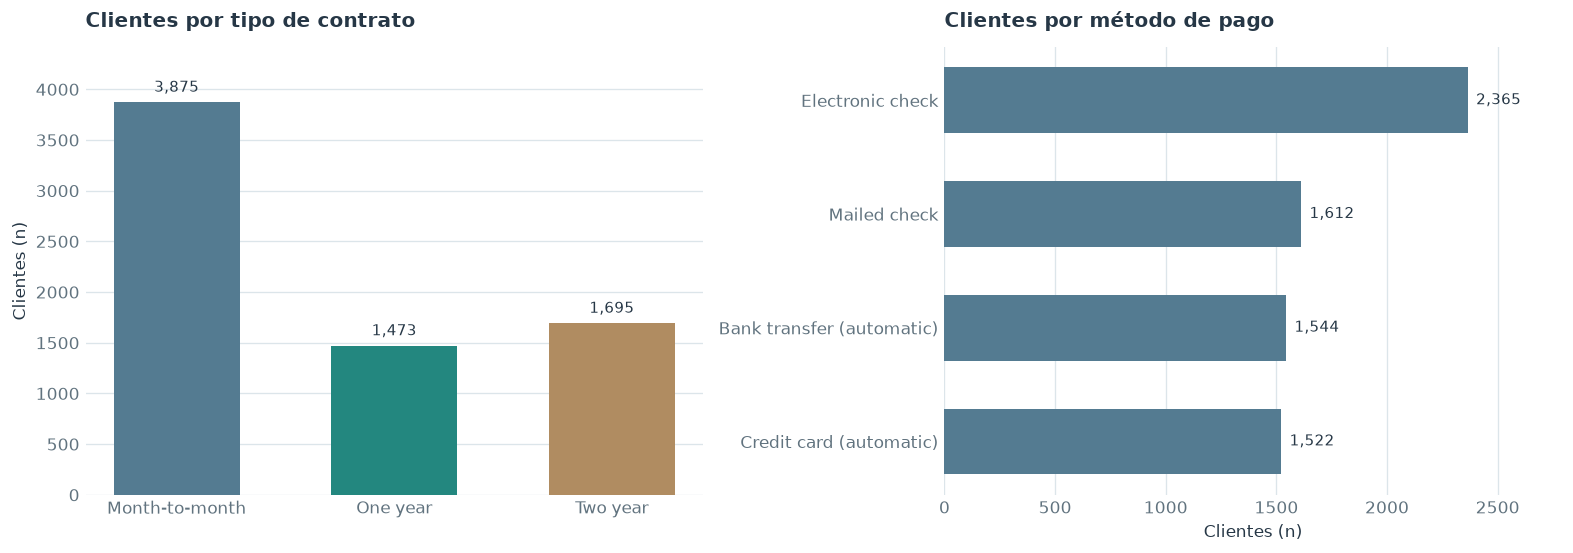

In [11]:
for columna in ["Type", "PaperlessBilling", "PaymentMethod", "EndDate"]:
    frecuencias = contract[columna].value_counts(dropna=False)
    tabla = pd.DataFrame({
        "clientes": frecuencias,
        "porcentaje": (100 * frecuencias / len(contract)).round(1),
    })
    print(f"\n--- {columna} ---")
    display(tabla)

# Distribuciones generales: denominador = número total de clientes de contract.
orden_contrato = ["Month-to-month", "One year", "Two year"]
conteo_tipos = contract["Type"].value_counts().reindex(orden_contrato)
conteo_pagos = contract["PaymentMethod"].value_counts().sort_values(ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), layout="constrained")
preparar_eje(axes[0]); preparar_eje(axes[1], horizontal=True)

barras = axes[0].bar(
    conteo_tipos.index, conteo_tipos.values,
    color=[COLORES_TIPO[t] for t in conteo_tipos.index], width=0.58,
)
axes[0].bar_label(barras, labels=[f"{v:,}" for v in conteo_tipos.values], padding=4, fontsize=9)
axes[0].set_ylim(0, conteo_tipos.max() * 1.14)
axes[0].set_ylabel("Clientes (n)")
axes[0].set_title("Clientes por tipo de contrato", loc="left", pad=12)

barras = axes[1].barh(conteo_pagos.index, conteo_pagos.values, color=COLOR["referencia"], height=0.58)
axes[1].bar_label(barras, labels=[f"{v:,}" for v in conteo_pagos.values], padding=5, fontsize=9)
axes[1].set_xlim(0, conteo_pagos.max() * 1.18)
axes[1].set_xlabel("Clientes (n)")
axes[1].set_title("Clientes por método de pago", loc="left", pad=12)
plt.show()

### A6. Unicidad de identificadores y ausencias encubiertas

**Pregunta:** ¿una fila de `contract` representa un cliente único? ¿Hay cadenas vacías o con espacios que `isna()` no detecta?

**Resultado guardado:** **7.043 IDs distintos en 7.043 filas**, sin IDs nulos ni repetidos. `TotalCharges` contiene **11 cadenas de espacios**. Estas cadenas no se convierten ni se eliminan del DataFrame original.

In [12]:
if "customerID" not in contract.columns:
    raise KeyError("No aparece customerID; hay que revisar el esquema antes de seguir.")

print("Filas:", len(contract))
print("IDs no nulos distintos:", contract["customerID"].nunique(dropna=True))
print("IDs nulos:", contract["customerID"].isna().sum())
print("IDs repetidos:", contract["customerID"].duplicated().sum())

columnas_texto = contract.select_dtypes(exclude="number").columns
calidad_texto = pd.DataFrame(index=contract.columns)
calidad_texto["nulos_isna"] = contract.isna().sum()
calidad_texto["vacios_o_espacios"] = 0
calidad_texto["espacios_en_extremos"] = 0

for columna in columnas_texto:
    original = contract[columna].astype("string")
    recortado = original.str.strip()
    calidad_texto.loc[columna, "vacios_o_espacios"] = int(recortado.eq("").fillna(False).sum())
    calidad_texto.loc[columna, "espacios_en_extremos"] = int(original.ne(recortado).fillna(False).sum())

display(calidad_texto)

Filas: 7043
IDs no nulos distintos: 7043
IDs nulos: 0
IDs repetidos: 0


,nulos_isna,vacios_o_espacios,espacios_en_extremos
customerID,0,0,0
BeginDate,0,0,0
EndDate,0,0,0
Type,0,0,0
PaperlessBilling,0,0,0
PaymentMethod,0,0,0
MonthlyCharges,0,0,0
TotalCharges,0,11,11


### A7. Calidad de los importes

**Pregunta:** ¿cómo se distribuye `MonthlyCharges` y por qué `TotalCharges` aparece como `object`?

El código genera `TOTAL_NUMERICO` como Serie auxiliar mediante `pd.to_numeric(..., errors="coerce")`. Esta operación permite detectar los **11 importes no convertibles** sin alterar `contract` ni decidir prematuramente su imputación.

**Criterio:** distinguir valores ausentes como representación de origen de errores numéricos reales antes de cualquier limpieza.

In [13]:
display(contract["MonthlyCharges"].describe().to_frame("MonthlyCharges"))

TOTAL_NUMERICO = pd.to_numeric(contract["TotalCharges"], errors="coerce")
no_convertibles = contract.loc[TOTAL_NUMERICO.isna(), "TotalCharges"]
print("TotalCharges no interpretables como número:", len(no_convertibles))
display(no_convertibles.value_counts(dropna=False).to_frame("registros"))

,MonthlyCharges
count,7043.000000
mean,64.761692
std,30.090047
min,18.250000
25%,35.500000
50%,70.350000
75%,89.850000
max,118.750000


TotalCharges no interpretables como número: 11


,registros
TotalCharges,
,11


### A8. Formatos de fechas contractuales

**Pregunta:** ¿cómo aparecen `BeginDate` y `EndDate`? La sustitución de dígitos se usa exclusivamente para reconocer patrones de formato, no para validar fechas ni demostrar cuál es la fecha de extracción.

**Observación:** `EndDate` contiene el literal `No` para contratos sin baja registrada y fechas para bajas; esta semántica se comprueba descriptivamente en B1–B2.

In [14]:
for columna in ["BeginDate", "EndDate"]:
    patrones = contract[columna].astype("string").str.replace(r"\d", "9", regex=True)
    print(f"\n--- Formatos de {columna} ---")
    display(patrones.value_counts(dropna=False).to_frame("registros"))


--- Formatos de BeginDate ---


,registros
BeginDate,
9999-99-99,7043



--- Formatos de EndDate ---


,registros
EndDate,
No,5174
9999-99-99 99:99:99,1869


### A9. Síntesis de la auditoría y decisiones de calidad

| Comprobación | Evidencia en las salidas guardadas | Decisión |
|---|---|---|
| Clave de `contract` | 7.043 filas, 7.043 identificadores no nulos distintos, 0 repetidos | Aceptar unicidad local; verificar relaciones con otras tablas en el Sprint 2. |
| Cobertura de tablas | `contract` 7.043; `internet` 5.517; `personal` 7.043; `phone` 6.361 | No asumir filas faltantes como errores ni ejecutar uniones en este notebook. |
| Modalidades de contrato | 3 tipos: mensual, un año, dos años | Mantener categorías originales, sin recodificar todavía. |
| Formato de `TotalCharges` | 11 cadenas con espacios | Trabajar con Serie auxiliar; no borrar filas ni imputar sin justificar. |
| Estado y fechas | `BeginDate` en formato de fecha; `EndDate` = `No` o fecha de baja | Evaluar solo fechas de contratos terminados; fecha de corte no confirmada. |

**Conclusión:** la auditoría inicial de `contract` es suficiente para el análisis retrospectivo de este cuaderno, pero la revisión semántica individual de los servicios y los cruces por `customerID` **siguen pendientes**.

**Siguiente bloque:** B. Estudiaremos las bajas ya registradas; este avance pertenece conceptualmente a fases exploratorias posteriores del roadmap y no sustituye la inspección detallada de las demás fuentes.

---
## B. Investigación retrospectiva de los contratos

**Población de interés:** clientes con fecha de cancelación registrada. Las comparaciones con todos los clientes se hacen únicamente cuando el cálculo exige un denominador para estimar la **proporción histórica observada** de cancelaciones.

**Orden del bloque:** B1 estados → B2 fechas → B3 duración → B4 tipo de contrato → B5 cargos por modalidad → B6 métodos de pago → B7 facturación sin papel → B8 calidad/fecha de corte → B9 síntesis contractual → B10–B12 investigación económica de los desertores.

**Restricción temporal:** la duración final calculada con `EndDate` solo describe clientes cuya baja ya ocurrió; **no es una característica válida para anticipar esa misma cancelación**. Sin historial de snapshots, una predicción retrospectiva anterior a la baja puede incorporar información futura sin querer.

### B1. Estado contractual y magnitud del abandono registrado

**Pregunta:** ¿qué fracción de los clientes tiene una fecha de baja en `EndDate`?

**Método:** `BAJA_OBSERVADA` es un indicador auxiliar para conteos retrospectivos. No equivale a una predicción de abandono en un horizonte futuro definido.

,clientes,porcentaje
EndDate,,
Sin fecha de baja,5174,73.5
Con fecha de baja,1869,26.5


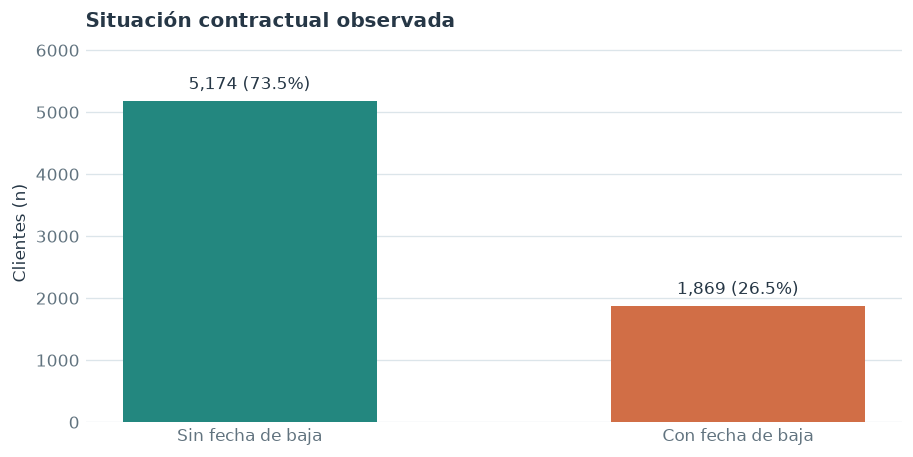

In [15]:
# Etiquetas auxiliares; NO modifican el DataFrame original.
BAJA_OBSERVADA = contract["EndDate"].ne("No")
ESTADO = BAJA_OBSERVADA.map({False: "Sin fecha de baja", True: "Con fecha de baja"})

orden_estado = ["Sin fecha de baja", "Con fecha de baja"]
conteo_estado = ESTADO.value_counts().reindex(orden_estado)
display(pd.DataFrame({
    "clientes": conteo_estado,
    "porcentaje": (100 * conteo_estado / len(contract)).round(1),
}))

fig, ax = plt.subplots(figsize=(7.5, 3.7), layout="constrained")
preparar_eje(ax)
barras = ax.bar(
    conteo_estado.index, conteo_estado.values,
    color=[COLOR["activo"], COLOR["baja"]], width=0.52,
)
ax.bar_label(
    barras,
    labels=[f"{v:,} ({100 * v / len(contract):.1f}%)" for v in conteo_estado.values],
    padding=5, fontsize=10,
)
ax.set_ylim(0, conteo_estado.max() * 1.18)
ax.set_ylabel("Clientes (n)")
ax.set_title("Situación contractual observada", loc="left", pad=10)
plt.show()

**Conclusión B1:** los resultados guardados registran **5.174 clientes sin baja (73,5 %)** y **1.869 con baja (26,5 %)**. Se trata de una prevalencia histórica en el archivo, no de una tasa mensual ni de una probabilidad de cancelar en los próximos 30 días. El desequilibrio real no es el 80/20 supuesto inicialmente.

### B2. Conversión auxiliar y coherencia de fechas

**Pregunta:** ¿las fechas se pueden convertir y las cancelaciones suceden después del inicio?

La transformación opera sobre Series auxiliares `FECHA_INICIO` y `FECHA_BAJA`; no modifica las columnas originales. `EndDate == "No"` se trata como ausente **solo** en la Serie de fechas de baja.

**Límite:** la presencia de cuatro fechas de baja distintas no constituye una serie temporal suficientemente amplia para interpretar estacionalidad.

In [16]:
FECHA_INICIO = pd.to_datetime(contract["BeginDate"], format="%Y-%m-%d", errors="raise")
FECHA_BAJA = pd.to_datetime(
    contract["EndDate"].mask(~BAJA_OBSERVADA),
    format="%Y-%m-%d %H:%M:%S",
    errors="raise",
)

print("Primera fecha de inicio:", FECHA_INICIO.min())
print("Última fecha de inicio:", FECHA_INICIO.max())
print("Primera fecha de baja:", FECHA_BAJA.min())
print("Última fecha de baja:", FECHA_BAJA.max())
print("Bajas previas al inicio:", (FECHA_BAJA < FECHA_INICIO).sum())

# Función útil para contratos que han terminado: meses de calendario entre fechas.
def meses_calendario(inicio, fin):
    return (fin.dt.year - inicio.dt.year) * 12 + (fin.dt.month - inicio.dt.month)

Primera fecha de inicio: 2013-10-01 00:00:00
Última fecha de inicio: 2020-02-01 00:00:00
Primera fecha de baja: 2019-10-01 00:00:00
Última fecha de baja: 2020-01-01 00:00:00
Bajas previas al inicio: 0


### B3. Permanencia final de los clientes que cancelaron

**Pregunta:** ¿cuánto duraron los contratos cancelados y cómo cambia esa duración entre las tres modalidades?

Se calcula `DURACION_BAJAS` **solo para contratos terminados**, mediante diferencia en meses de calendario. No debe confundirse con la antigüedad observada de un cliente activo ni con una duración contractual proyectada.

,count,min,25%,50%,75%,max
Type,,,,,,
Month-to-month,1655.0,1.0,2.00,7.0,21.0,71.0
One year,166.0,2.0,33.00,48.0,59.0,72.0
Two year,48.0,25.0,55.75,65.5,70.0,72.0


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_3304\1660676613.py:20: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp = ax.boxplot(


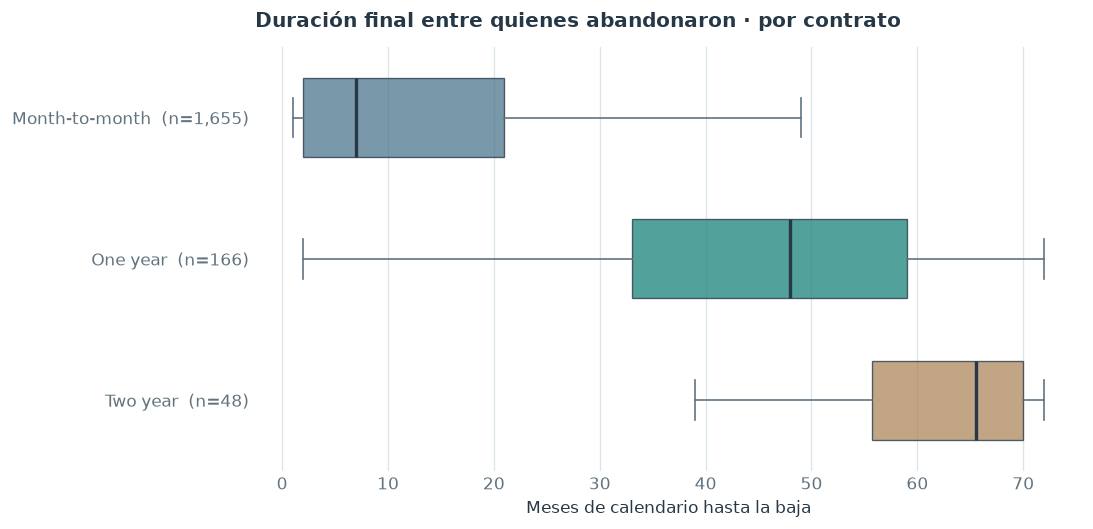

In [17]:
ORDEN_CONTRATO = ["Month-to-month", "One year", "Two year"]
BAJAS = contract.loc[BAJA_OBSERVADA].copy()
if set(contract["Type"].dropna().unique()) != set(ORDEN_CONTRATO):
    raise ValueError("Revisar las categorías de Type antes de ordenar resultados")

DURACION_BAJAS = meses_calendario(
    FECHA_INICIO.loc[BAJA_OBSERVADA], FECHA_BAJA.loc[BAJA_OBSERVADA]
)
resumen_duracion = (
    pd.DataFrame({"Type": BAJAS["Type"], "meses": DURACION_BAJAS})
    .groupby("Type")["meses"]
    .describe(percentiles=[0.25, 0.5, 0.75])
    .loc[ORDEN_CONTRATO, ["count", "min", "25%", "50%", "75%", "max"]]
)
display(resumen_duracion)

fig, ax = plt.subplots(figsize=(9, 4.3), layout="constrained")
preparar_eje(ax, horizontal=True)
series = [DURACION_BAJAS.loc[BAJAS["Type"].eq(tipo)].dropna() for tipo in ORDEN_CONTRATO]
bp = ax.boxplot(
    series, vert=False, tick_labels=ORDEN_CONTRATO, patch_artist=True,
    widths=0.56, showfliers=False, medianprops={"color": COLOR["tinta"], "linewidth": 2},
    boxprops={"edgecolor": COLOR["tinta"], "linewidth": 0.8},
    whiskerprops={"color": COLOR["muted"]}, capprops={"color": COLOR["muted"]},
)
for patch, tipo in zip(bp["boxes"], ORDEN_CONTRATO):
    patch.set_facecolor(COLORES_TIPO[tipo])
    patch.set_alpha(0.78)
ax.set_yticks(range(1, 4), [f"{t}  (n={len(s):,})" for t, s in zip(ORDEN_CONTRATO, series)])
ax.invert_yaxis()
ax.set_xlabel("Meses de calendario hasta la baja")
ax.set_title("Duración final entre quienes abandonaron · por contrato", loc="left", pad=12)
plt.show()

**Conclusión B3:** la mediana de permanencia entre desertores fue **7 meses (Month-to-month, n = 1.655)**, **48 meses (One year, n = 166)** y **65 meses (Two year, n = 48)**. Los grupos presentan tamaños muy diferentes; comparar esas medianas no demuestra que la modalidad contractual *cause* más permanencia. La duración de los contratos activos está censurada y aquí no se trata como duración final.

### B4. Prevalencia histórica de cancelación por contrato

**Pregunta:** ¿qué proporción de los clientes de **cada** modalidad tiene una baja registrada?

**Denominador:** todos los clientes de esa modalidad, tanto activos como cancelados. Esto evita confundir el porcentaje de desertores que usa un plan con la tasa de cancelación observada dentro del plan.

,clientes,bajas,proporcion,proporcion_pct
Type,,,,
Month-to-month,3875,1655,0.427097,42.7
One year,1473,166,0.112695,11.3
Two year,1695,48,0.028319,2.8


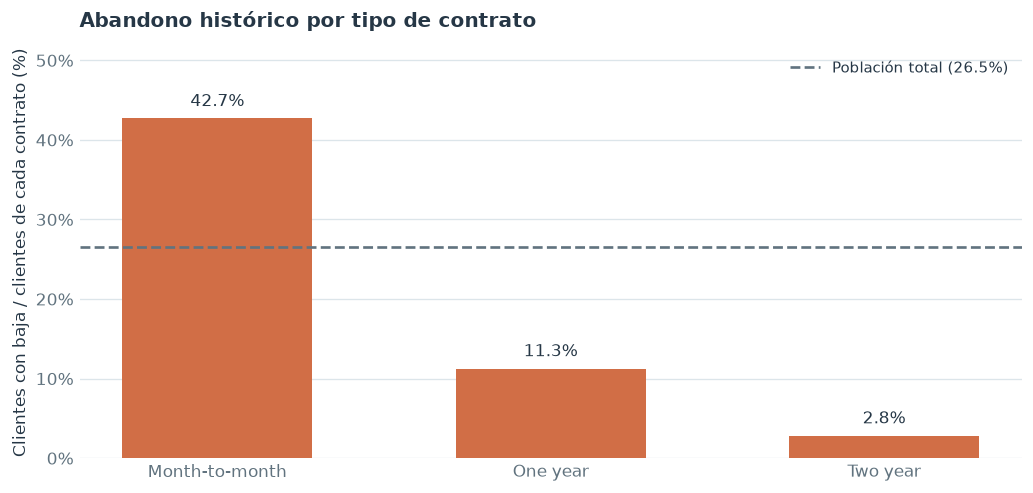

In [18]:
tasa_contrato = (
    pd.DataFrame({"Type": contract["Type"], "baja": BAJA_OBSERVADA})
    .groupby("Type")["baja"]
    .agg(clientes="size", bajas="sum", proporcion="mean")
    .reindex(ORDEN_CONTRATO)
)
display(tasa_contrato.assign(proporcion_pct=lambda t: (100 * t["proporcion"]).round(1)))

fig, ax = plt.subplots(figsize=(8.5, 4), layout="constrained")
preparar_eje(ax)
y = tasa_contrato["proporcion"] * 100
barras = ax.bar(tasa_contrato.index, y, color=COLOR["baja"], width=0.57)
ax.bar_label(barras, labels=[f"{v:.1f}%" for v in y], padding=5, fontsize=10)
ax.axhline(BAJA_OBSERVADA.mean() * 100, color=COLOR["muted"], linestyle="--",
           linewidth=1.6, label=f"Población total ({BAJA_OBSERVADA.mean():.1%})")
ax.set_ylim(0, max(y.max() * 1.21, BAJA_OBSERVADA.mean() * 115))
ax.yaxis.set_major_formatter(PCT)
ax.set_ylabel("Clientes con baja / clientes de cada contrato (%)")
ax.set_title("Abandono histórico por tipo de contrato", loc="left", pad=12)
ax.legend(loc="upper right", fontsize=9)
plt.show()

**Conclusión B4:** **Month-to-month: 1.655/3.875 = 42,7 %**, **One year: 166/1.473 = 11,3 %** y **Two year: 48/1.695 = 2,8 %**. Las diferencias ameritan un análisis condicionado por antigüedad, mensualidad y servicios. Esta tabla no identifica causas de cancelación ni riesgos futuros.

### B5. Cargos mensuales y acumulados según contrato entre desertores

**Pregunta:** ¿cómo difieren las distribuciones de `MonthlyCharges` y `TotalCharges` entre las modalidades contractuales de quienes cancelaron?

**Interpretación:** `MonthlyCharges` corresponde al cargo registrado, no a una serie histórica de tarifas. `TotalCharges` acumula facturación y depende fuertemente de la permanencia. Las gráficas descriptivas preservan los denominadores y normalizaciones definidos en el código.

TotalCharges no convertible entre quienes se fueron: 0


MonthlyCharges               TotalCharges                  
                        count   mean median        count     mean   median
Type                                                                      
Month-to-month           1655  73.02  79.05         1655  1164.46   514.00
One year                  166  85.05  95.05          166  4066.21  4098.52
Two year                   48  86.78  97.28           48  5432.36  5874.25

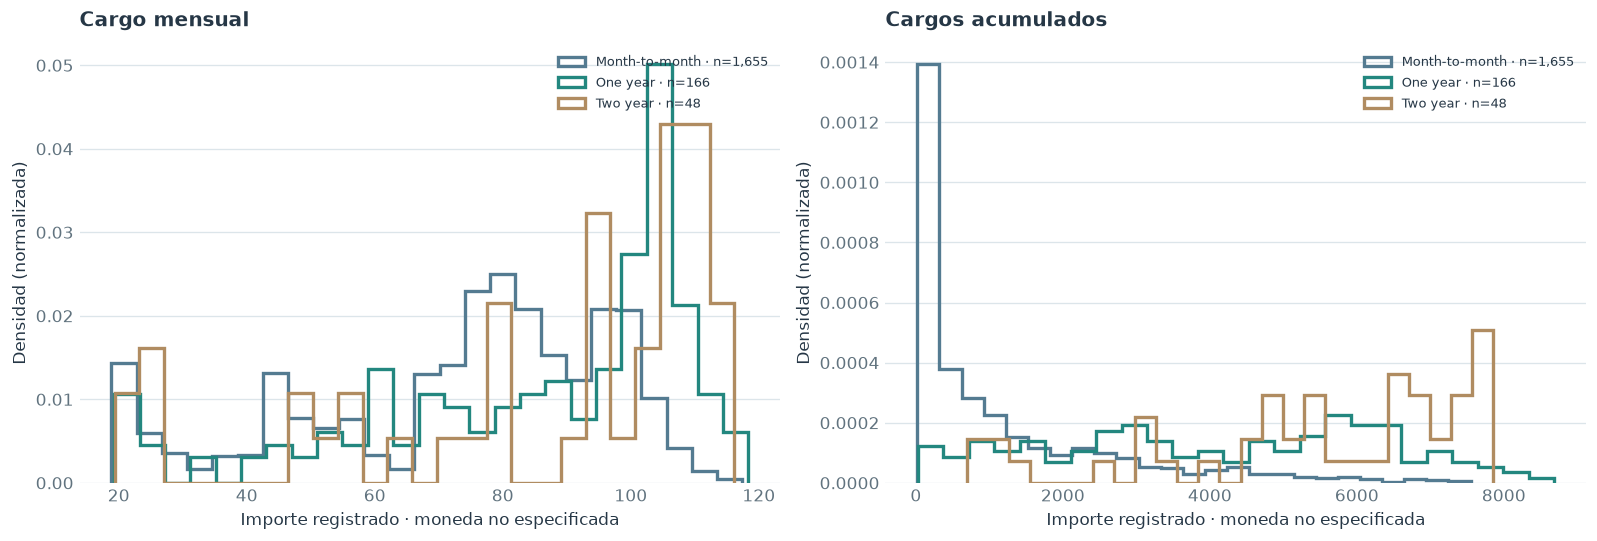

In [19]:
GASTO_BAJAS = pd.DataFrame({
    "Type": BAJAS["Type"],
    "MonthlyCharges": BAJAS["MonthlyCharges"],
    "TotalCharges": TOTAL_NUMERICO.loc[BAJA_OBSERVADA],
})

print("TotalCharges no convertible entre quienes se fueron:", GASTO_BAJAS["TotalCharges"].isna().sum())
display(
    GASTO_BAJAS.groupby("Type")[["MonthlyCharges", "TotalCharges"]]
    .agg(["count", "mean", "median"])
    .reindex(ORDEN_CONTRATO).round(2)
)

# Comparamos FORMAS, no cantidades: cada distribución se normaliza por su propio grupo.
fig, axes = plt.subplots(1, 2, figsize=(13.2, 4.4), layout="constrained")
for ax, columna, titulo in zip(
    axes, ["MonthlyCharges", "TotalCharges"], ["Cargo mensual", "Cargos acumulados"]
):
    preparar_eje(ax)
    for tipo in ORDEN_CONTRATO:
        serie = GASTO_BAJAS.loc[GASTO_BAJAS["Type"].eq(tipo), columna].dropna()
        ax.hist(serie, bins=25, density=True, histtype="step", linewidth=2,
                label=f"{tipo} · n={len(serie):,}", color=COLORES_TIPO[tipo])
    ax.set_title(titulo, loc="left", pad=10)
    ax.set_xlabel("Importe registrado · moneda no especificada")
    ax.set_ylabel("Densidad (normalizada)")
    ax.legend(loc="upper right", fontsize=8)
plt.show()

**Conclusión B5:** las comparaciones de cargos entre contratos terminados describen **niveles de facturación**, pero no permiten interpretar `TotalCharges` como fidelidad ni atribuir el abandono al precio. Las densidades del gráfico se normalizan dentro de las modalidades para comparar formas sin confundir tamaños muestrales.

**Decisión:** estudiar después `TotalCharges` frente a permanencia para entender su componente acumulativo (B10–B12).

### B6. Método de pago y cancelación observada

**Pregunta:** ¿se asocia `PaymentMethod` con el abandono? ¿Persisten diferencias descriptivas al separar por tipo de contrato?

El bloque incluye chi-cuadrado, V de Cramér y tasas por métodos de pago. Las pruebas son exploratorias: un *p* muy pequeño no mide magnitud ni establece causalidad, y sus inferencias dependen de los supuestos estadísticos.

,clientes,bajas,proporcion,proporcion_pct
PaymentMethod,,,,
Electronic check,2365,1071,0.452854,45.3
Mailed check,1612,308,0.191067,19.1
Bank transfer (automatic),1544,258,0.167098,16.7
Credit card (automatic),1522,232,0.152431,15.2


Chi2=648.14, gl=3, p=3.68e-140, V de Cramér=0.303
Celdas con frecuencia esperada < 5: 0


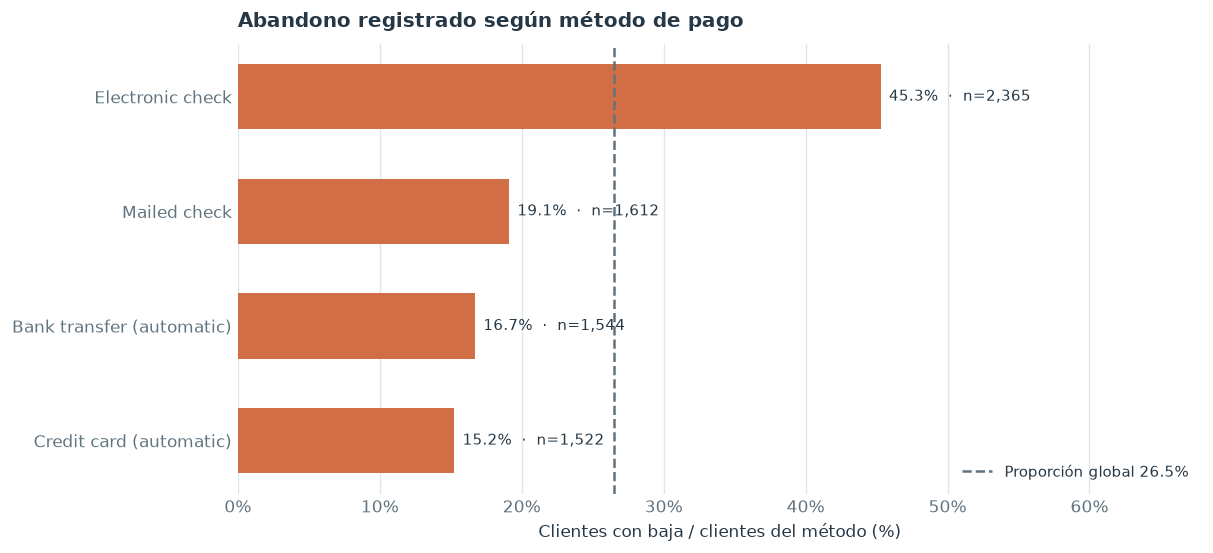

In [20]:
from scipy.stats import chi2_contingency

# Chi-cuadrado + V de Cramér para tablas de contingencia categóricas.
def asociacion_categorica(variable, baja):
    tabla = pd.crosstab(variable, baja)
    chi2, p_valor, gl, esperados = chi2_contingency(tabla)
    v = np.sqrt(chi2 / (tabla.to_numpy().sum() * (min(tabla.shape) - 1)))
    return chi2, p_valor, gl, v, int((esperados < 5).sum())

pago = (
    pd.DataFrame({"PaymentMethod": contract["PaymentMethod"], "baja": BAJA_OBSERVADA})
    .groupby("PaymentMethod")["baja"]
    .agg(clientes="size", bajas="sum", proporcion="mean")
    .sort_values("proporcion", ascending=False)
)
display(pago.assign(proporcion_pct=(100 * pago["proporcion"]).round(1)))
chi2, p, gl, v, esperados_pequenos = asociacion_categorica(contract["PaymentMethod"], BAJA_OBSERVADA)
print(f"Chi2={chi2:.2f}, gl={gl}, p={p:.3g}, V de Cramér={v:.3f}")
print("Celdas con frecuencia esperada < 5:", esperados_pequenos)

# Tasas con denominador propio por método de pago.
fig, ax = plt.subplots(figsize=(10, 4.5), layout="constrained")
preparar_eje(ax, horizontal=True)
orden_grafico = pago.sort_values("proporcion")
y = orden_grafico["proporcion"] * 100
barras = ax.barh(orden_grafico.index, y, color=COLOR["baja"], height=0.57)
ax.bar_label(
    barras,
    labels=[f"{v:.1f}%  ·  n={n:,}" for v, n in zip(y, orden_grafico["clientes"])],
    padding=5, fontsize=9,
)
ax.axvline(BAJA_OBSERVADA.mean() * 100, color=COLOR["muted"], linestyle="--", linewidth=1.5,
           label=f"Proporción global {BAJA_OBSERVADA.mean():.1%}")
ax.set_xlim(0, max(y.max() * 1.5, BAJA_OBSERVADA.mean() * 140))
ax.xaxis.set_major_formatter(PCT)
ax.set_xlabel("Clientes con baja / clientes del método (%)")
ax.set_title("Abandono registrado según método de pago", loc="left", pad=10)
ax.legend(loc="lower right", fontsize=9)
plt.show()

**Conclusión B6:** la asociación observada entre método de pago y cancelación tiene **χ² = 648,14**, **p ≈ 3,68 × 10⁻¹⁴⁰** y **V de Cramér ≈ 0,303**, según la salida guardada. La fortaleza de la asociación no identifica mecanismos causales. El cruce siguiente permite ver las tasas *dentro* de cada modalidad contractual, con sus denominadores.

In [21]:
# Comparamos tasas dentro de cada tipo de contrato y mostramos tamaños de grupo.
comparacion_pago_contrato = pd.crosstab(
    contract["PaymentMethod"], contract["Type"],
    values=BAJA_OBSERVADA, aggfunc="mean"
).reindex(columns=ORDEN_CONTRATO)
conteos_pago_contrato = pd.crosstab(
    contract["PaymentMethod"], contract["Type"]
).reindex(columns=ORDEN_CONTRATO)

print("Porcentaje con baja dentro de cada combinación (pago × contrato):")
display((comparacion_pago_contrato * 100).round(1))
print("Denominadores de cada combinación:")
display(conteos_pago_contrato)

Porcentaje con baja dentro de cada combinación (pago × contrato):


Type,Month-to-month,One year,Two year
PaymentMethod,,,
Bank transfer (automatic),34.1,9.7,3.4
Credit card (automatic),32.8,10.3,2.2
Electronic check,53.7,18.4,7.7
Mailed check,31.6,6.8,0.8


Denominadores de cada combinación:


Type,Month-to-month,One year,Two year
PaymentMethod,,,
Bank transfer (automatic),589,391,564
Credit card (automatic),543,398,581
Electronic check,1850,347,168
Mailed check,893,337,382


### B7. Facturación sin papel y método de pago

**Pregunta:** ¿se observa una asociación con `PaperlessBilling` y cómo cambia al considerar tipo contractual o forma de pago?

Un cruce estratificado permite describir heterogeneidad entre grupos, pero **no** equivale a un control causal completo de antigüedad, servicios y otros factores.

,clientes,bajas,proporcion,proporcion_pct
PaperlessBilling,,,,
No,2872,469,0.163301,16.3
Yes,4171,1400,0.335651,33.6


Chi2=258.28, gl=1, p=4.07e-58, V de Cramér=0.191
Celdas con frecuencia esperada < 5: 0
Tasa histórica de abandono por tipo de contrato y PaperlessBilling (%):


PaperlessBilling,No,Yes
Type,,
Month-to-month,31.5,48.3
One year,7.1,14.8
Two year,1.6,4.2


Denominadores de los grupos:


PaperlessBilling,No,Yes
Type,,
Month-to-month,1289,2586
One year,673,800
Two year,910,785


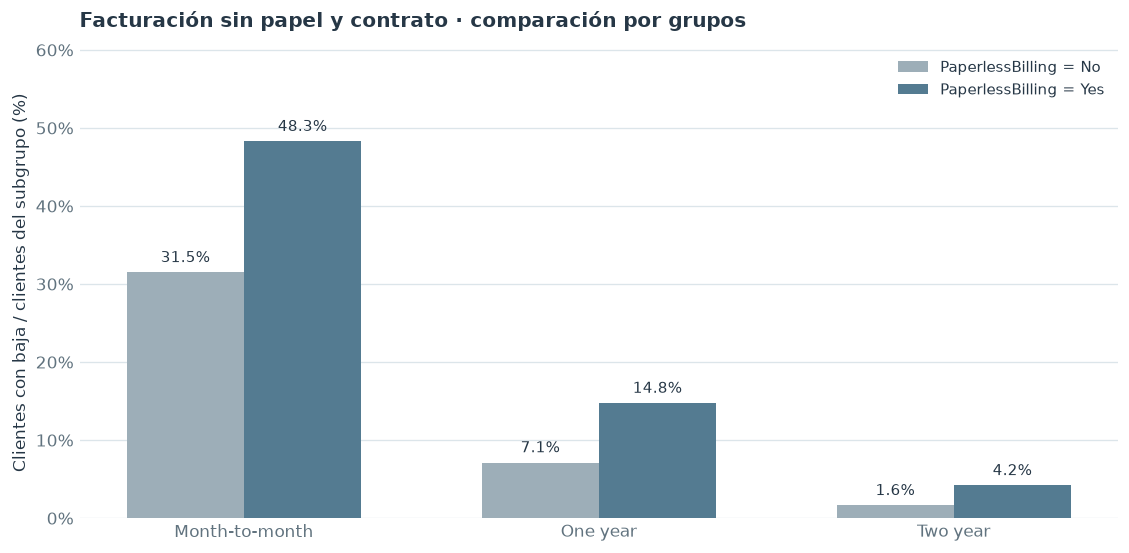

In [22]:
paperless = (
    pd.DataFrame({"PaperlessBilling": contract["PaperlessBilling"], "baja": BAJA_OBSERVADA})
    .groupby("PaperlessBilling")["baja"]
    .agg(clientes="size", bajas="sum", proporcion="mean")
    .reindex(["No", "Yes"])
)
display(paperless.assign(proporcion_pct=(100 * paperless["proporcion"]).round(1)))
chi2, p, gl, v, esperados_pequenos = asociacion_categorica(contract["PaperlessBilling"], BAJA_OBSERVADA)
print(f"Chi2={chi2:.2f}, gl={gl}, p={p:.3g}, V de Cramér={v:.3f}")
print("Celdas con frecuencia esperada < 5:", esperados_pequenos)

comparacion_papel_contrato = pd.crosstab(
    contract["Type"], contract["PaperlessBilling"],
    values=BAJA_OBSERVADA, aggfunc="mean",
).reindex(index=ORDEN_CONTRATO, columns=["No", "Yes"])
conteos_papel_contrato = pd.crosstab(
    contract["Type"], contract["PaperlessBilling"]
).reindex(index=ORDEN_CONTRATO, columns=["No", "Yes"])

print("Tasa histórica de abandono por tipo de contrato y PaperlessBilling (%):")
display((100 * comparacion_papel_contrato).round(1))
print("Denominadores de los grupos:")
display(conteos_papel_contrato)

# Barras agrupadas con colores estables para las dos categorías de facturación.
fig, ax = plt.subplots(figsize=(9.3, 4.5), layout="constrained")
preparar_eje(ax)
centros = np.arange(len(ORDEN_CONTRATO))
ancho = 0.33
for desplazamiento, opcion, color in [(-ancho / 2, "No", COLOR["paperless_no"]),
                                      (ancho / 2, "Yes", COLOR["paperless_yes"])]:
    valores = (100 * comparacion_papel_contrato[opcion]).to_numpy()
    barras = ax.bar(centros + desplazamiento, valores, width=ancho, color=color,
                    label=f"PaperlessBilling = {opcion}")
    ax.bar_label(barras, labels=[f"{v:.1f}%" for v in valores], padding=4, fontsize=9)
ax.set_xticks(centros, ORDEN_CONTRATO)
ax.set_ylim(0, (100 * comparacion_papel_contrato).max().max() * 1.25)
ax.yaxis.set_major_formatter(PCT)
ax.set_ylabel("Clientes con baja / clientes del subgrupo (%)")
ax.set_title("Facturación sin papel y contrato · comparación por grupos", loc="left", pad=12)
ax.legend(loc="upper right", fontsize=9)
plt.show()

,clientes,paperless_pct,cargo_mensual_mediana
PaymentMethod,,,
Electronic check,2365,73.7,80.550
Mailed check,1612,40.7,34.700
Bank transfer (automatic),1544,57.7,73.100
Credit card (automatic),1522,58.0,73.025


Abandono histórico por método de pago × PaperlessBilling (%):


PaperlessBilling,No,Yes
PaymentMethod,,
Electronic check,32.7,49.8
Mailed check,13.5,27.3
Bank transfer (automatic),11.0,20.9
Credit card (automatic),10.0,19.0


Denominadores de cada combinación:


PaperlessBilling,No,Yes
PaymentMethod,,
Electronic check,623,1742
Mailed check,956,656
Bank transfer (automatic),653,891
Credit card (automatic),640,882


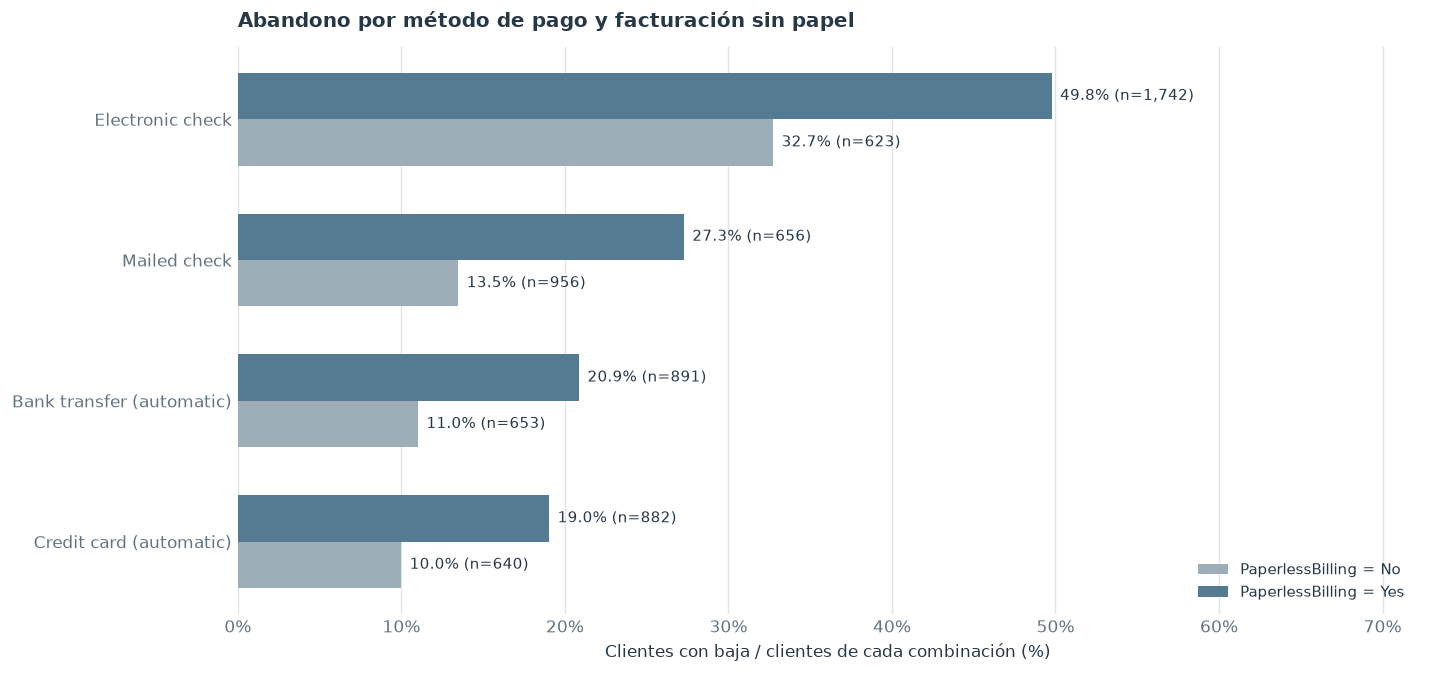

In [23]:
# Perfil de los métodos de pago: contextos diferentes, no explicaciones psicológicas.
perfil_pago = pd.DataFrame({
    "clientes": contract["PaymentMethod"].value_counts(),
    "paperless_pct": (100 * contract["PaperlessBilling"].eq("Yes")
                      .groupby(contract["PaymentMethod"]).mean()).round(1),
    "cargo_mensual_mediana": contract.groupby("PaymentMethod")["MonthlyCharges"].median(),
}).reindex(pago.index)
display(perfil_pago)

cruce = pd.crosstab(
    contract["PaymentMethod"], contract["PaperlessBilling"],
    values=BAJA_OBSERVADA, aggfunc="mean",
).reindex(index=pago.index, columns=["No", "Yes"])
conteos_cruce = pd.crosstab(
    contract["PaymentMethod"], contract["PaperlessBilling"]
).reindex(index=pago.index, columns=["No", "Yes"])
print("Abandono histórico por método de pago × PaperlessBilling (%):")
display((cruce * 100).round(1))
print("Denominadores de cada combinación:")
display(conteos_cruce)

# Representación horizontal agrupada: nombres largos y denominadores explícitos.
fig, ax = plt.subplots(figsize=(11.8, 5.5), layout="constrained")
preparar_eje(ax, horizontal=True)
orden_pago = pago.index.tolist()[::-1]
y_centro = np.arange(len(orden_pago))
altura = 0.33
for despl, opcion, color in [(-altura / 2, "No", COLOR["paperless_no"]),
                              (altura / 2, "Yes", COLOR["paperless_yes"])]:
    tasas = (100 * cruce.loc[orden_pago, opcion]).to_numpy()
    tamaños = conteos_cruce.loc[orden_pago, opcion].to_numpy()
    barras = ax.barh(y_centro + despl, tasas, height=altura, color=color,
                     label=f"PaperlessBilling = {opcion}")
    ax.bar_label(barras,
                 labels=[f"{pct:.1f}% (n={n:,})" for pct, n in zip(tasas, tamaños)],
                 padding=5, fontsize=9)
ax.set_yticks(y_centro, orden_pago)
ax.set_xlim(0, (100 * cruce).max().max() * 1.45)
ax.xaxis.set_major_formatter(PCT)
ax.set_xlabel("Clientes con baja / clientes de cada combinación (%)")
ax.set_title("Abandono por método de pago y facturación sin papel", loc="left", pad=12)
ax.legend(loc="lower right", fontsize=9)
plt.show()

**Conclusión B7:** con `PaperlessBilling = Yes` se observan **1.400/4.171 = 33,6 %** de bajas; con `No`, **469/2.872 = 16,3 %**. La asociación global presenta **χ² ≈ 258,28**, **p ≈ 4,07 × 10⁻⁵⁸**, **V de Cramér ≈ 0,191**.

En las cuatro modalidades de pago, la tasa observada con facturación sin papel supera a la correspondiente sin esa opción; por ejemplo, **Electronic check: 49,8 % vs. 32,7 %**. No se ha demostrado que activar facturación electrónica provoque cancelaciones: composición de contratos, servicios y antigüedad pueden intervenir.

### B8. `TotalCharges` vacío y fecha de corte pendiente

**Pregunta:** ¿quiénes tienen `TotalCharges` no convertible? Las **11 cadenas con espacios** se encuentran en contratos **sin baja** y con `BeginDate = 2020-02-01`, según los resultados guardados.

**Interpretación permitida:** podría tratarse de clientes muy recientes sin facturación acumulada, pero la fecha **2020-02-01 sigue siendo un indicio, no una fecha de extracción confirmada**. No se sustituyen los cargos por cero ni se calcula antigüedad para activos con esa suposición.

In [24]:
pendientes_total = pd.DataFrame({
    "BeginDate": contract.loc[TOTAL_NUMERICO.isna(), "BeginDate"],
    "EndDate": contract.loc[TOTAL_NUMERICO.isna(), "EndDate"],
})
print("Registros con TotalCharges no convertible, agrupados por fechas:")
display(pendientes_total.value_counts(dropna=False).to_frame("clientes"))

Registros con TotalCharges no convertible, agrupados por fechas:


,,clientes
BeginDate,EndDate,
2020-02-01,No,11


### B9. Síntesis contractual antes del análisis económico detallado

| Pregunta | Resultado contrastado con las salidas | Alcance |
|---|---|---|
| ¿Cuántos clientes cancelaron? | **1.869/7.043 = 26,5 %** | Prevalencia histórica, no riesgo futuro. |
| ¿Influye el tipo de contrato? | **42,7 %** mensual; **11,3 %** anual; **2,8 %** dos años | Asociación sin inferencia causal. |
| ¿Cuánto duraron las bajas? | Medianas **7**, **48** y **65 meses**, por tipo | Duraciones finales solo de desertores. |
| ¿Se asocia la facturación sin papel? | **33,6 %** con PaperlessBilling frente a **16,3 %** sin papel | Asociación sujeta a confusión. |
| ¿Se asocia el pago? | **χ² = 648,14**; **V de Cramér ≈ 0,303** | Medida de asociación, no importancia causal. |
| ¿Qué requiere limpieza? | **11** importes de `TotalCharges` con espacios | No se imputa ni se borra en esta fase. |

**Hipótesis abiertas para futuras uniones:**

- **H1:** ¿la diferencia por contrato se mantiene entre clientes con antigüedad y cargos comparables?
- **H2:** ¿las asociaciones de pagos y PaperlessBilling se mantienen al considerar servicios contratados?
- **H3:** ¿las cancelaciones tempranas contienen distintos perfiles económicos y de servicios?

**Precauciones:** (i) la duración final de quienes cancelaron no estaba disponible antes de la baja; (ii) `MonthlyCharges` no es una serie temporal; (iii) las bajas registradas entre octubre de 2019 y enero de 2020 no permiten inferir estacionalidad; (iv) la fecha de corte de los clientes activos no está confirmada.

**Estado:** auditoría contractual descriptiva terminada. Continúan a continuación los experimentos económicos y de clustering **ya ejecutados en este mismo cuaderno**. No se han unido tablas ni entrenado modelos supervisados.

### B10. Gasto histórico acumulado exclusivamente entre desertores

**Pregunta:** ¿cuánto suman los `TotalCharges` de quienes cancelaron y cómo se distribuye el total por cliente?

**Población:** `BAJA_OBSERVADA == True`. La suma es **facturación acumulada histórica**, **no** una estimación de ingresos futuros perdidos.

In [25]:

# TotalCharges exclusivamente de clientes que cancelaron
total_bajas = TOTAL_NUMERICO.loc[BAJA_OBSERVADA].dropna()

print("Clientes que abandonaron:", len(total_bajas))
print("Gasto acumulado de todos los desertores:", round(total_bajas.sum(), 2))

display(total_bajas.describe().round(2))


Clientes que abandonaron: 1869
Gasto acumulado de todos los desertores: 2862926.9


count    1869.00
mean     1531.80
std      1890.82
min        18.85
25%       134.50
50%       703.55
75%      2331.30
max      8684.80
Name: TotalCharges, dtype: float64

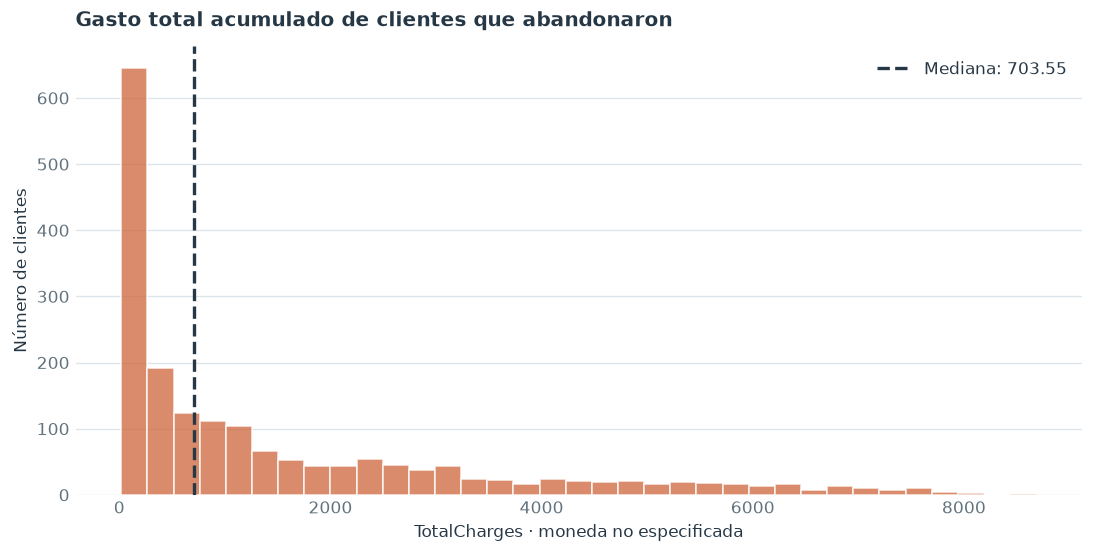

In [26]:

fig, ax = plt.subplots(figsize=(9, 4.5), layout="constrained")

preparar_eje(ax)

ax.hist(
    total_bajas,
    bins=35,
    color=COLOR["baja"],
    alpha=0.8,
    edgecolor="white"
)

ax.axvline(
    total_bajas.median(),
    color=COLOR["tinta"],
    linestyle="--",
    linewidth=2,
    label=f"Mediana: {total_bajas.median():,.2f}"
)

ax.set_title(
    "Gasto total acumulado de clientes que abandonaron",
    loc="left",
    pad=12
)
ax.set_xlabel("TotalCharges · moneda no especificada")
ax.set_ylabel("Número de clientes")
ax.legend(frameon=False)

plt.show()


#### Conclusión B10 · Facturación acumulada de quienes cancelaron

**Población:** 1.869 desertores, sin incluir contratos activos.

- **Suma histórica de `TotalCharges`: 2.862.926,90** unidades monetarias, **no** pérdidas futuras imputables al Churn.
- **Media:** 1.531,80; **mediana:** 703,55; **Q1:** 134,50; **Q3:** 2.331,30; **máximo:** 8.684,80.
- La media supera ampliamente a la mediana: **distribución asimétrica hacia valores altos**. Importes bajos pueden ser compatibles con cancelaciones tempranas, pero el importe no identifica por sí mismo la duración.

**Siguiente pregunta:** ¿hasta qué punto el gasto acumulado está relacionado con los meses de permanencia (B11)?

### B11. Asociación entre permanencia final y facturación acumulada

**Pregunta:** ¿cuánta información sobre `TotalCharges` aporta la duración hasta la baja?

Se utiliza la misma población de 1.869 desertores y se calculan correlaciones de Pearson y Spearman. El gráfico de dispersión muestra tanto la tendencia como la heterogeneidad de importes para duraciones similares.

In [27]:

# Relación entre permanencia y gasto acumulado de los desertores

relacion_gasto = pd.DataFrame({
    "meses": DURACION_BAJAS,
    "TotalCharges": TOTAL_NUMERICO.loc[BAJA_OBSERVADA]
}).dropna()

print("Clientes analizados:", len(relacion_gasto))

print("\nCorrelación de Pearson:")
print(round(relacion_gasto["meses"].corr(
    relacion_gasto["TotalCharges"], method="pearson"
), 3))

print("\nCorrelación de Spearman:")
print(round(relacion_gasto["meses"].corr(
    relacion_gasto["TotalCharges"], method="spearman"
), 3))


Clientes analizados: 1869

Correlación de Pearson:
0.954

Correlación de Spearman:
0.971


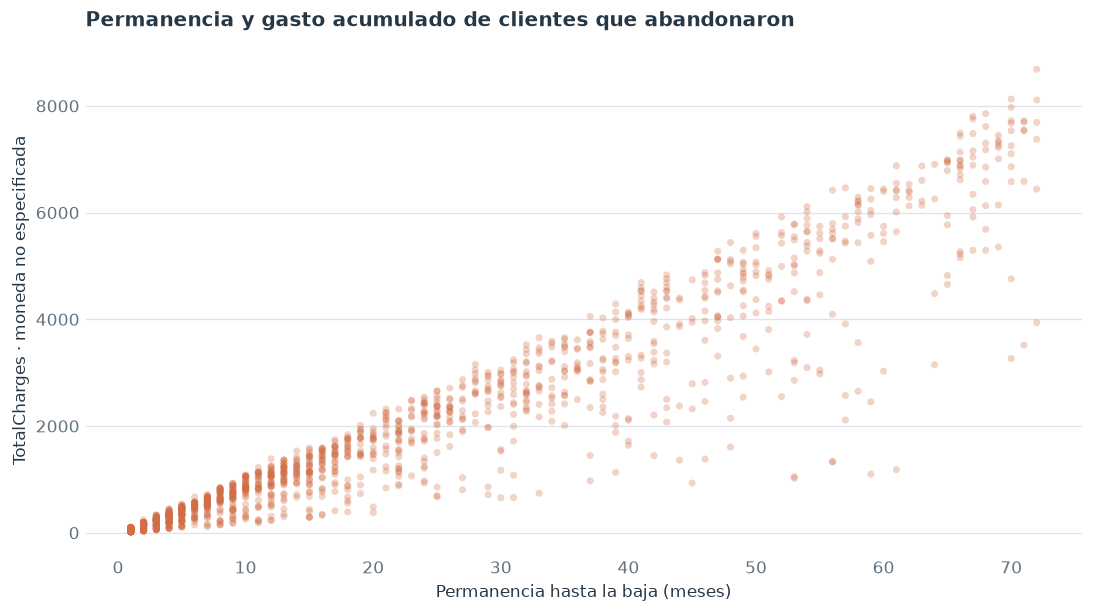

In [28]:

fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")

preparar_eje(ax)

ax.scatter(
    relacion_gasto["meses"],
    relacion_gasto["TotalCharges"],
    color=COLOR["baja"],
    alpha=0.30,
    s=18,
    edgecolors="none"
)

ax.set_title(
    "Permanencia y gasto acumulado de clientes que abandonaron",
    loc="left",
    pad=12
)

ax.set_xlabel("Permanencia hasta la baja (meses)")
ax.set_ylabel("TotalCharges · moneda no especificada")

plt.show()


#### Conclusión B11 · Permanencia frente a gasto acumulado

**Población:** 1.869 clientes con baja registrada.

- **Pearson = 0,954**, asociación lineal positiva muy fuerte.
- **Spearman = 0,971**, asociación monótona positiva muy fuerte.
- El gráfico confirma tendencia ascendente y mayor amplitud de valores de gasto con permanencias largas.

**Interpretación:** la asociación es esperable porque `TotalCharges` acumula pagos a lo largo del tiempo. El cuadrado de Pearson (≈ **0,91**) representa la proporción de variación explicada por una regresión lineal simple **en esta muestra**, no un efecto causal del tiempo ni una garantía de generalización.

**Hipótesis H3.3:** con una permanencia igual o similar, las diferencias en cargos mensuales podrían explicar buena parte de las diferencias de gasto total. Se contrasta en B12.

### B12. Diferencias económicas a permanencia similar

**Pregunta:** ¿por qué algunos desertores acumularon más facturación que otros aun permaneciendo tiempos parecidos?

**Diseño:** (1) agrupar por intervalos de permanencia, (2) comparar mensualidades con un boxplot, (3) observar un subgrupo de duración **exactamente 24 meses**, (4) evaluar la aproximación `MonthlyCharges × meses` primero en ese subgrupo y después en los 1.869 desertores.

Los intervalos tienen distinto número de clientes; los cargos mensuales registrados no equivalen necesariamente a un promedio tarifario histórico.

In [29]:

# Perfiles económicos de clientes que abandonaron

perfil_economico = pd.DataFrame({
    "meses": DURACION_BAJAS,
    "MonthlyCharges": BAJAS["MonthlyCharges"],
    "TotalCharges": TOTAL_NUMERICO.loc[BAJA_OBSERVADA],
    "Type": BAJAS["Type"]
}).dropna()

# Agrupamos clientes con duraciones similares
intervalos = [0, 6, 12, 24, 48, 72]
etiquetas = ["1–6", "7–12", "13–24", "25–48", "49–72"]

perfil_economico["grupo_permanencia"] = pd.cut(
    perfil_economico["meses"],
    bins=intervalos,
    labels=etiquetas,
    include_lowest=True
)

resumen_economico = (
    perfil_economico
    .groupby("grupo_permanencia", observed=True)
    .agg(
        clientes=("TotalCharges", "size"),
        gasto_total_mediano=("TotalCharges", "median"),
        cargo_mensual_mediano=("MonthlyCharges", "median"),
        gasto_total_q1=("TotalCharges", lambda x: x.quantile(0.25)),
        gasto_total_q3=("TotalCharges", lambda x: x.quantile(0.75))
    )
    .round(2)
)

display(resumen_economico)


,clientes,gasto_total_mediano,cargo_mensual_mediano,gasto_total_q1,gasto_total_q3
grupo_permanencia,,,,,
1–6,784,89.40,70.30,66.35,223.60
7–12,253,713.00,80.45,527.90,865.80
13–24,294,1383.72,84.52,1097.65,1739.15
25–48,325,2896.40,89.10,2365.15,3626.10
49–72,213,5643.40,99.90,4816.70,6581.90


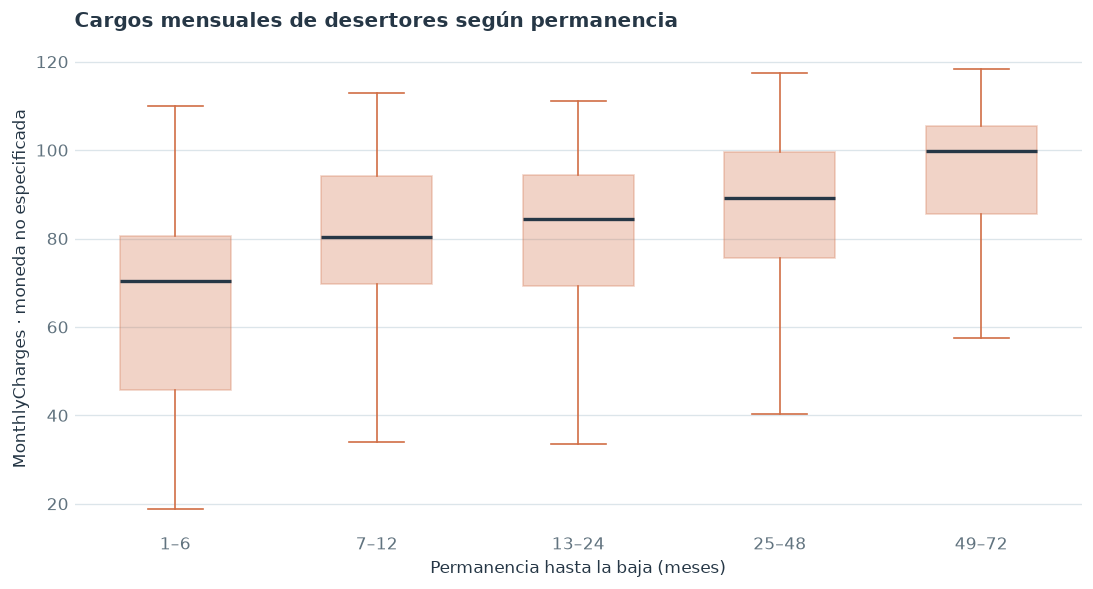

In [30]:

fig, ax = plt.subplots(
    figsize=(9, 4.8),
    layout="constrained"
)

preparar_eje(ax)

datos_boxplot = [
    perfil_economico.loc[
        perfil_economico["grupo_permanencia"] == grupo,
        "MonthlyCharges"
    ].dropna()
    for grupo in etiquetas
]

bp = ax.boxplot(
    datos_boxplot,
    tick_labels=etiquetas,
    patch_artist=True,
    widths=0.55,
    showfliers=False,
    medianprops={
        "color": COLOR["tinta"],
        "linewidth": 2
    },
    boxprops={"edgecolor": COLOR["baja"]},
    whiskerprops={"color": COLOR["baja"]},
    capprops={"color": COLOR["baja"]}
)

for caja in bp["boxes"]:
    caja.set_facecolor(COLOR["baja"])
    caja.set_alpha(0.30)

ax.set_title(
    "Cargos mensuales de desertores según permanencia",
    loc="left",
    pad=12
)
ax.set_xlabel("Permanencia hasta la baja (meses)")
ax.set_ylabel("MonthlyCharges · moneda no especificada")

plt.show()


Clientes con 24 meses: 23


,MonthlyCharges,TotalCharges
count,23.00,23.00
mean,81.31,1940.68
std,21.65,524.87
min,39.10,933.30
25%,65.53,1556.62
50%,90.35,2165.05
75%,99.02,2399.55
max,104.65,2542.45


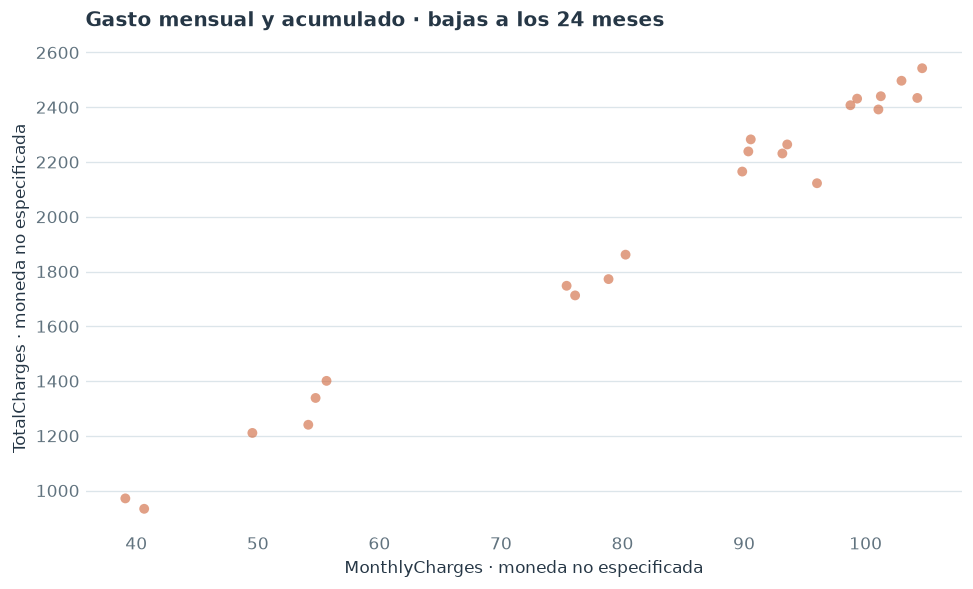

In [31]:

# Clientes que cancelaron después de exactamente 24 meses
mes_objetivo = 24

mismo_tiempo = perfil_economico.loc[
    perfil_economico["meses"] == mes_objetivo
].copy()

print(f"Clientes con {mes_objetivo} meses:", len(mismo_tiempo))

display(
    mismo_tiempo[["MonthlyCharges", "TotalCharges"]]
    .describe()
    .round(2)
)

if not mismo_tiempo.empty:
    fig, ax = plt.subplots(
        figsize=(8, 4.8),
        layout="constrained"
    )

    preparar_eje(ax)

    ax.scatter(
        mismo_tiempo["MonthlyCharges"],
        mismo_tiempo["TotalCharges"],
        color=COLOR["baja"],
        alpha=0.65,
        s=35,
        edgecolors="none"
    )

    ax.set_title(
        f"Gasto mensual y acumulado · bajas a los {mes_objetivo} meses",
        loc="left",
        pad=12
    )
    ax.set_xlabel("MonthlyCharges · moneda no especificada")
    ax.set_ylabel("TotalCharges · moneda no especificada")

    plt.show()


#### B12.1. Consistencia contable en 23 desertores con 24 meses

Calculamos `TotalCharges` estimado como `MonthlyCharges × 24` y examinamos las **diferencias individuales**, no solo la media; los errores positivos y negativos pueden compensarse.

In [32]:

# Comprobación económica para clientes que abandonaron a los 24 meses

comparacion_24 = mismo_tiempo.copy()

comparacion_24["total_estimado"] = (
    comparacion_24["MonthlyCharges"]
    * comparacion_24["meses"]
)

comparacion_24["diferencia"] = (
    comparacion_24["TotalCharges"]
    - comparacion_24["total_estimado"]
)

comparacion_24["error_pct"] = (
    100 * comparacion_24["diferencia"]
    / comparacion_24["total_estimado"]
)

display(
    comparacion_24[
        [
            "MonthlyCharges",
            "TotalCharges",
            "total_estimado",
            "diferencia",
            "error_pct"
        ]
    ].describe().round(2)
)

print(
    "Error absoluto mediano:",
    round(comparacion_24["diferencia"].abs().median(), 2)
)


,MonthlyCharges,TotalCharges,total_estimado,diferencia,error_pct
count,23.00,23.00,23.00,23.00,23.00
mean,81.31,1940.68,1951.41,-10.73,-0.55
std,21.65,524.87,519.67,69.35,3.66
min,39.10,933.30,938.40,-181.55,-7.88
25%,65.53,1556.62,1572.60,-60.55,-3.38
50%,90.35,2165.05,2168.40,10.15,0.42
75%,99.02,2399.55,2376.60,31.87,1.81
max,104.65,2542.45,2511.60,109.35,5.03


Error absoluto mediano: 42.3


#### B12.2. Comprobación descriptiva en toda la población de desertores

Aplicamos el mismo cociente de error porcentual a todos los registros de `perfil_economico` con duración mayor que cero. El **error porcentual absoluto** permite medir cobertura de la aproximación sin cancelación de signos.

In [33]:

# Evaluar la aproximación en todos los clientes que abandonaron

evaluacion_total = perfil_economico.loc[
    perfil_economico["meses"] > 0
].copy()

evaluacion_total["total_estimado"] = (
    evaluacion_total["MonthlyCharges"]
    * evaluacion_total["meses"]
)

evaluacion_total["error_pct"] = (
    100
    * (
        evaluacion_total["TotalCharges"]
        - evaluacion_total["total_estimado"]
    )
    / evaluacion_total["total_estimado"]
)

print("Clientes evaluados:", len(evaluacion_total))

print(
    "Error porcentual absoluto mediano:",
    round(evaluacion_total["error_pct"].abs().median(), 2),
    "%"
)

print(
    "Clientes con error absoluto ≤ 5 %:",
    round(
        (evaluacion_total["error_pct"].abs() <= 5).mean() * 100,
        2
    ),
    "%"
)

print(
    "Clientes con error absoluto ≤ 10 %:",
    round(
        (evaluacion_total["error_pct"].abs() <= 10).mean() * 100,
        2
    ),
    "%"
)


Clientes evaluados: 1869
Error porcentual absoluto mediano: 1.77 %
Clientes con error absoluto ≤ 5 %: 79.94 %
Clientes con error absoluto ≤ 10 %: 94.17 %


#### Conclusión B12 · H3.3 — Relación económica entre mensualidad, duración y gasto acumulado

**Experimento controlado descriptivamente por permanencia:** entre los **23 desertores de 24 meses**, los cargos mensuales oscilan entre **39,10 y 104,65**, y los cargos acumulados entre **933,30 y 2.542,45**. El gasto total medio observado fue **1.940,68**, frente a **1.951,41** estimados con `MonthlyCharges × meses` (diferencia media **−10,73**). Que la diferencia media sea pequeña **no implica** que todos los errores individuales lo sean.

**Extensión a los 1.869 desertores:**

- Error porcentual **absoluto mediano: 1,77 %**.
- **79,94 %** con error absoluto ≤ 5 %.
- **94,17 %** con error absoluto ≤ 10 %.

**Conclusión:** el importe acumulado se aproxima bien por mensualidad registrada × duración final para la mayoría de desertores. Hay **información parcialmente redundante**; podrían existir cambios de tarifa, descuentos o diferencias de cómputo temporal no observadas. No se deduce que la tarifa haya sido constante.

**Pendiente opcional:** estudiar el **5,83 %** de registros con desviación superior al 10 %, especialmente por duración corta y modalidad contractual.

**Nota para ML:** la duración final retrospectiva y el `TotalCharges` final pueden contener información futura si se usan para simular predicciones previas a la cancelación. Este bloque describe el pasado, no constituye un conjunto de características predictivas.

---
## C. Primer clustering no supervisado · investigación retrospectiva de desertores

**Pregunta central H4:** ¿cómo se organizan los clientes que cancelaron según **permanencia hasta la baja** y **cargo mensual registrado**? ¿Los grupos resultantes muestran composiciones diferentes de contratos, pagos y facturación sin papel?

**Método:** K-Means con `StandardScaler` sobre dos variables (`meses`, `MonthlyCharges`). `TotalCharges` queda fuera para no enfatizar varias veces el componente acumulativo; `Type`, `PaymentMethod` y `PaperlessBilling` se reservan para **interpretación externa**.

**Importante:** la duración final es admisible para este experimento *retrospectivo*, pero **no** para un futuro modelo que pretenda anticipar la baja antes de que ocurra. Ningún cluster representa un riesgo prospectivo.

### C1. Preparación de matriz numérica y escalado

In [34]:

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

# Una observación por cliente que abandonó
clientes_cluster = pd.DataFrame({
    "meses": DURACION_BAJAS,
    "MonthlyCharges": BAJAS["MonthlyCharges"],
    "TotalCharges": TOTAL_NUMERICO.loc[BAJA_OBSERVADA],
    "Type": BAJAS["Type"],
    "PaymentMethod": BAJAS["PaymentMethod"],
    "PaperlessBilling": BAJAS["PaperlessBilling"]
}).dropna(subset=["meses", "MonthlyCharges"])

# Solo dos variables participan en el agrupamiento
variables_cluster = ["meses", "MonthlyCharges"]

escalador = StandardScaler()

X_cluster = escalador.fit_transform(
    clientes_cluster[variables_cluster]
)

print("Clientes para clustering:", len(clientes_cluster))
print("Dimensiones de la matriz:", X_cluster.shape)

display(clientes_cluster[variables_cluster].describe().round(2))


Clientes para clustering: 1869
Dimensiones de la matriz: (1869, 2)


,meses,MonthlyCharges
count,1869.00,1869.00
mean,17.98,74.44
std,19.53,24.67
min,1.00,18.85
25%,2.00,56.15
50%,10.00,79.65
75%,29.00,94.20
max,72.00,118.35


### C2. Selección exploratoria del número de clusters

Se comparan `k = 2…6` utilizando **Silhouette Score** y **inercia**. La silueta más alta entre estas alternativas favorece una configuración, pero no prueba la existencia de grupos naturales.

,k,silhouette,inercia
0,2,0.457,2002.287
1,3,0.513,997.558
2,4,0.462,786.491
3,5,0.466,606.773
4,6,0.421,494.023


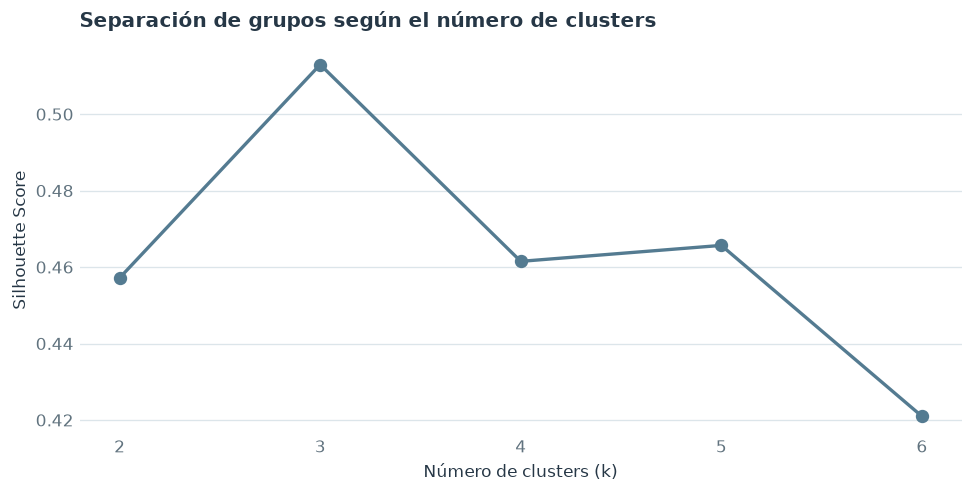

In [35]:

resultados_k = []

for k in range(2, 7):
    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    etiquetas = modelo.fit_predict(X_cluster)

    puntuacion = silhouette_score(
        X_cluster,
        etiquetas
    )

    resultados_k.append({
        "k": k,
        "silhouette": puntuacion,
        "inercia": modelo.inertia_
    })

resultados_k = pd.DataFrame(resultados_k)

display(resultados_k.round(3))

fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
preparar_eje(ax)

ax.plot(
    resultados_k["k"],
    resultados_k["silhouette"],
    marker="o",
    color=COLOR["referencia"],
    linewidth=2,
    markersize=7
)

ax.set_xticks(resultados_k["k"])
ax.set_xlabel("Número de clusters (k)")
ax.set_ylabel("Silhouette Score")
ax.set_title(
    "Separación de grupos según el número de clusters",
    loc="left",
    pad=12
)

plt.show()


### C3. Representación geométrica de los tres perfiles

Se elige el mayor Silhouette Score entre los `k` probados y se grafica cada asignación junto a su centroide en unidades originales. Los colores identifican clusters; **no** categorías de riesgo ni grupos causales.

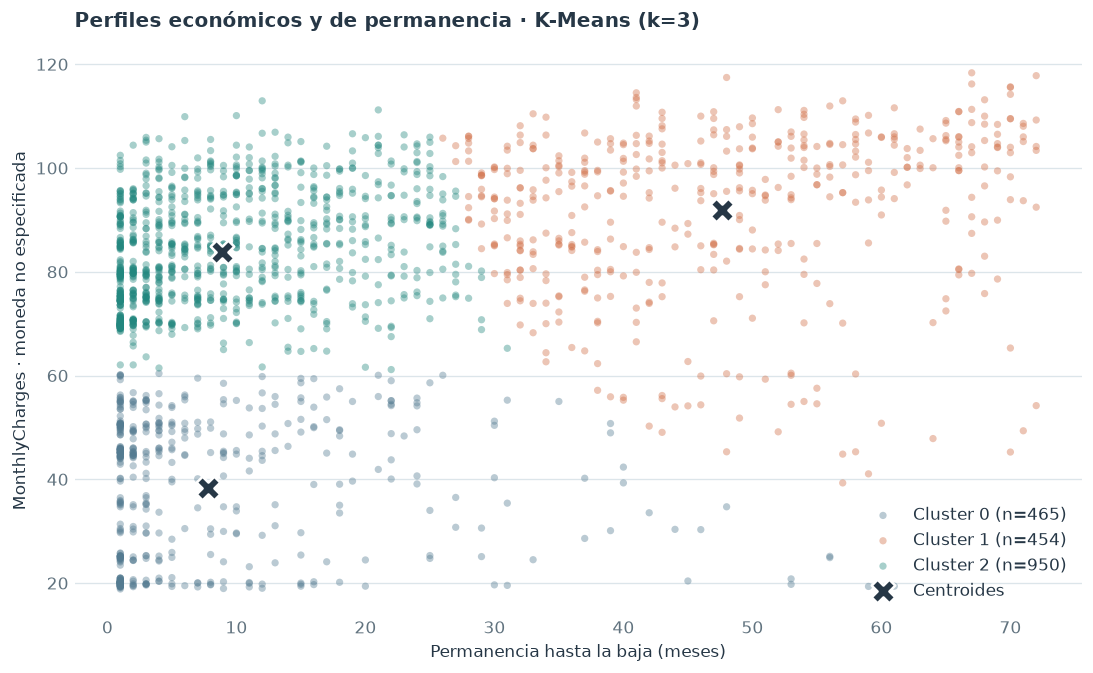

Número de clusters seleccionado: 3


In [36]:

k_elegido = int(
    resultados_k.loc[
        resultados_k["silhouette"].idxmax(),
        "k"
    ]
)

modelo_final = KMeans(
    n_clusters=k_elegido,
    random_state=42,
    n_init=20
)

clientes_cluster["cluster"] = modelo_final.fit_predict(X_cluster)

# Centros expresados nuevamente en las unidades originales
centros = escalador.inverse_transform(
    modelo_final.cluster_centers_
)

colores_cluster = [
    "#547B91",
    "#D16E46",
    "#23877F",
    "#B08C61",
    "#846C98",
    "#8B9BA5"
]

fig, ax = plt.subplots(figsize=(9, 5.5), layout="constrained")
preparar_eje(ax)

for cluster in sorted(clientes_cluster["cluster"].unique()):
    grupo = clientes_cluster.loc[
        clientes_cluster["cluster"] == cluster
    ]

    ax.scatter(
        grupo["meses"],
        grupo["MonthlyCharges"],
        color=colores_cluster[cluster],
        alpha=0.40,
        s=19,
        label=f"Cluster {cluster} (n={len(grupo)})",
        edgecolors="none"
    )

ax.scatter(
    centros[:, 0],
    centros[:, 1],
    marker="X",
    s=200,
    color=COLOR["tinta"],
    edgecolors="white",
    linewidths=1.5,
    label="Centroides",
    zorder=5
)

ax.set_title(
    f"Perfiles económicos y de permanencia · K-Means (k={k_elegido})",
    loc="left",
    pad=12
)

ax.set_xlabel("Permanencia hasta la baja (meses)")
ax.set_ylabel("MonthlyCharges · moneda no especificada")
ax.legend(frameon=False)

plt.show()

print("Número de clusters seleccionado:", k_elegido)


### C3.1. Perfil económico y composición de variables externas

Se calculan tamaños, medianas y porcentajes de cluster; luego se inspeccionan `Type`, `PaymentMethod` y `PaperlessBilling`, **que no participaron en la distancia euclidiana**. Estos porcentajes son **composiciones entre desertores**, no tasas de Churn.

In [37]:

# Tamaño y características económicas de cada grupo
resumen_clusters = (
    clientes_cluster
    .groupby("cluster")
    .agg(
        clientes=("meses", "size"),
        permanencia_mediana=("meses", "median"),
        cargo_mensual_mediano=("MonthlyCharges", "median"),
        gasto_total_mediano=("TotalCharges", "median")
    )
    .round(2)
)

resumen_clusters["porcentaje"] = (
    100 * resumen_clusters["clientes"] / len(clientes_cluster)
).round(1)

display(resumen_clusters)

# ¿Cómo se distribuyen los tipos de contrato en cada cluster?
composicion_contrato = (
    pd.crosstab(
        clientes_cluster["cluster"],
        clientes_cluster["Type"],
        normalize="index"
    )
    .reindex(columns=ORDEN_CONTRATO)
    .mul(100)
    .round(1)
)

print("Composición porcentual por tipo de contrato:")
display(composicion_contrato)

# ¿Cómo se distribuyen los métodos de pago?
composicion_pago = (
    pd.crosstab(
        clientes_cluster["cluster"],
        clientes_cluster["PaymentMethod"],
        normalize="index"
    )
    .mul(100)
    .round(1)
)

print("Composición porcentual por método de pago:")
display(composicion_pago)

# Facturación sin papel
composicion_paperless = (
    pd.crosstab(
        clientes_cluster["cluster"],
        clientes_cluster["PaperlessBilling"],
        normalize="index"
    )
    .mul(100)
    .round(1)
)

print("Composición porcentual por PaperlessBilling:")
display(composicion_paperless)


,clientes,permanencia_mediana,cargo_mensual_mediano,gasto_total_mediano,porcentaje
cluster,,,,,
0,465,3.0,43.65,102.75,24.9
1,454,47.0,96.12,4136.45,24.3
2,950,7.0,82.95,528.70,50.8


Composición porcentual por tipo de contrato:


Type,Month-to-month,One year,Two year
cluster,,,
0,94.0,4.9,1.1
1,62.6,28.0,9.5
2,98.3,1.7,0.0


Composición porcentual por método de pago:


PaymentMethod,Bank transfer (automatic),Credit card (automatic),Electronic check,Mailed check
cluster,,,,
0,10.3,11.4,40.2,38.1
1,21.1,21.6,52.9,4.4
2,12.0,8.5,67.8,11.7


Composición porcentual por PaperlessBilling:


PaperlessBilling,No,Yes
cluster,,
0,43.4,56.6
1,19.6,80.4
2,18.7,81.3


### C4. Índice de representación de los métodos de pago

Para distinguir sobrerrepresentación relativa de una categoría frecuente, dividimos su proporción dentro del cluster por su proporción **en toda la población de desertores**.

In [38]:

# Comparar la composición de los clusters
# con la distribución global de los desertores.

pago_global = (
    clientes_cluster["PaymentMethod"]
    .value_counts(normalize=True)
)

pago_por_cluster = pd.crosstab(
    clientes_cluster["cluster"],
    clientes_cluster["PaymentMethod"],
    normalize="index"
)

indice_representacion = (
    pago_por_cluster.div(pago_global, axis="columns")
    .round(2)
)

print("Índice de representación por método de pago")
print("1.00 = misma proporción que en todos los desertores")

display(indice_representacion)


Índice de representación por método de pago
1.00 = misma proporción que en todos los desertores


PaymentMethod,Bank transfer (automatic),Credit card (automatic),Electronic check,Mailed check
cluster,,,,
0,0.75,0.92,0.70,2.31
1,1.53,1.74,0.92,0.27
2,0.87,0.69,1.18,0.71


### C4. Representación relativa de métodos de pago: contraste externo

**Método:** se compara la proporción de cada forma de pago dentro del cluster con su proporción entre **todos los desertores**. Un índice **1,00** significa igual frecuencia relativa; mayor que 1,00, sobrerrepresentación; menor, infrarrepresentación.

| Cluster | Perfil descriptivo | Índices destacados |
|---|---|---|
| **0** (465; 24,9 %) | Cancelación temprana, cargo bajo | `Mailed check` **2,31**; `Electronic check` **0,70**. |
| **1** (454; 24,3 %) | Permanencia prolongada, cargo alto | Tarjeta automática **1,74**; transferencia automática **1,53**; `Mailed check` **0,27**. |
| **2** (950; 50,8 %) | Cancelación relativamente temprana, cargo alto | `Electronic check` **1,18**; tarjeta automática **0,69**. |

**Hallazgo H4:** dentro de los desertores de menor permanencia se distinguen perfiles económicos y administrativos. Las variables de pago, `Type` y `PaperlessBilling` no participaron en K-Means, de modo que sirven de contexto externo descriptivo.

**Límite:** índice de representación **no** equivale a tasa de abandono, riesgo, causa ni validación supervisada. La diferencia de categorías puede deberse a su relación con los dos ejes empleados en la segmentación.

### C5. Estabilidad de inicialización mediante Adjusted Rand Index (ARI)

Se conserva `k = 3`, se ajusta K-Means con cinco semillas y se compara la partición con la referencia mediante ARI, que es invariante a permutaciones de etiquetas. La prueba evalúa **reproducibilidad de la inicialización**, no estabilidad del perfil al cambiar clientes o variables.

In [39]:

from sklearn.metrics import adjusted_rand_score

# Comparar la solución de k=3 con distintas semillas
semillas = [0, 21, 42, 99, 123]
etiquetas_referencia = clientes_cluster["cluster"].to_numpy()

resultados_estabilidad = []

for semilla in semillas:
    modelo = KMeans(
        n_clusters=3,
        random_state=semilla,
        n_init=20
    )

    etiquetas_nuevas = modelo.fit_predict(X_cluster)

    resultados_estabilidad.append({
        "semilla": semilla,
        "ARI": adjusted_rand_score(
            etiquetas_referencia,
            etiquetas_nuevas
        )
    })

display(
    pd.DataFrame(resultados_estabilidad).round(3)
)


,semilla,ARI
0,0,1.0
1,21,1.0
2,42,1.0
3,99,1.0
4,123,1.0


#### Resultado C5 · Estabilidad entre inicializaciones

La tabla anterior registra **ARI = 1,000** para las cinco semillas evaluadas (**0, 21, 42, 99 y 123**). La partición de los 1.869 clientes coincide exactamente con la solución de referencia, aun cuando K-Means utilice identificadores numéricos distintos para los clusters.

**Interpretación:** la segmentación de tres grupos es **estable frente a estas inicializaciones** bajo los mismos datos y las mismas dos características. Esta prueba no comprueba estabilidad ante remuestreo, nuevos clientes, otras variables o diferentes escalados.

### C6. Validación conjunta: separación, interpretación y estabilidad

| Criterio | Evidencia del notebook | Conclusión autorizada |
|---|---|---|
| **Selección de k** | Silhouette para k = 2, 3, 4, 5 y 6: **0,457; 0,513; 0,462; 0,466; 0,421** | **k = 3** es la mejor de las cinco alternativas ensayadas. |
| **Separación** | Silhouette **0,513** con k = 3 | Separación **moderada**, no categorías naturales demostradas. |
| **Interpretabilidad** | Tres perfiles distintos de permanencia/cargo mensual y composición de pagos, contratos y PaperlessBilling | Segmentación descriptiva útil para formular preguntas sobre servicios y clientes activos. |
| **Inicialización** | ARI **1,000** con cinco semillas | Resultado estable frente a esas inicializaciones, no frente a perturbaciones de la muestra. |

**Decisión experimental:** mantener **tres clusters retrospectivos** como resultado reproducible de esta configuración. No llamar «alto riesgo» a ninguno: todos los miembros de los tres grupos ya habían cancelado. No extrapolar los arquetipos a clientes activos sin investigar primero las características disponibles en el momento de predicción.

---
## D. Cierre de investigación · contratos y primera segmentación de desertores

**Estado:** notebook cerrado como **hito independiente de investigación retrospectiva**; salidas guardadas y código de los experimentos conservados.

### D1. Hallazgos consolidados

1. **Base contractual:** 7.043 clientes distintos; 1.869 con baja histórica (**26,5 %**). `TotalCharges` contiene 11 valores en blanco representados como espacios.
2. **Patrones contractuales:** abandono histórico de **42,7 %** en mes a mes, **11,3 %** en un año y **2,8 %** en dos años. Son asociaciones, no efectos causales.
3. **Economía del abandono:** `TotalCharges` acumulado entre desertores = **2.862.926,90**; mediana **703,55**. La relación con duración final es muy fuerte (**Pearson 0,954; Spearman 0,971**).
4. **Aproximación económica:** `MonthlyCharges × meses` reproduce `TotalCharges` con error absoluto mediano **1,77 %** y error ≤ 10 % en **94,17 %** de los desertores.
5. **Segmentación exploratoria:** K-Means sobre duración final y mensualidad, estandarizadas; **k = 3**, **Silhouette 0,513**, **ARI 1,000** en cinco inicializaciones.

| Cluster | n | % de desertores | Permanencia mediana | Mensualidad mediana | TotalCharges mediano | Etiqueta de trabajo |
|---|---:|---:|---:|---:|---:|---|
| **0** | 465 | 24,9 % | 3 meses | 43,65 | 102,75 | Temprano / cargo bajo |
| **1** | 454 | 24,3 % | 47 meses | 96,12 | 4.136,45 | Prolongado / cargo alto |
| **2** | 950 | 50,8 % | 7 meses | 82,95 | 528,70 | Temprano / cargo alto |

### D2. Alcance y límites

- El clustering **no estima probabilidades de cancelación**; se entrenó exclusivamente con clientes que ya habían abandonado.
- Las características `duracion_final` y gasto acumulado a la fecha de baja **no deben utilizarse** para fingir predicciones realizadas antes de esa fecha. A futuro tendremos que definir un corte temporal y características conocidas en ese momento.
- Las asociaciones de contrato, pago y PaperlessBilling no permiten inferir motivaciones personales ni causalidad.
- La fecha de extracción sigue sin confirmarse; los 11 valores vacíos de `TotalCharges` permanecen sin imputar.
- La estabilidad ARI se refiere a inicialización, no a robustez entre diferentes muestras o espacios de características.
- Este notebook **no** completa aún el análisis individual profundo de las tablas de servicios ni la unión customer-level del Sprint 2.

### D3. Decisiones y continuidad

**Decisión:** congelar el notebook como `notebooks/01_contract_eda_clustering.ipynb`, manteniendo código, figuras y resultados. Las investigaciones siguientes se desarrollarán en nuevos notebooks; no reescribir retrospectivamente estas conclusiones sin nueva evidencia.

**Siguiente etapa propuesta:** `02_eda_servicios.ipynb` para estudiar `internet.csv` y `phone.csv` de manera independiente y, posteriormente, `personal.csv` y la auditoría de relaciones por `customerID`. Al conectar poblaciones, comparar tasas de abandono y distribución de perfiles **con denominadores válidos**, no solo composición de los clusters de desertores.

**Criterio de verificación local:** ejecutar **Restart Kernel → Run All**, comprobar que todas las celdas siguen funcionando con `data/raw/`, conservar las figuras y registrar el resultado en la bitácora de decisiones. Esta edición es **documental**: el código ejecutable y el orden fueron preservados.

In [40]:

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

# Toda la población, sin utilizar Churn
variables = [
    "MonthlyCharges",
    "Type",
    "PaymentMethod",
    "PaperlessBilling"
]

poblacion_cluster = contract[
    ["customerID"] + variables
].copy()

# Comprobaciones de calidad
assert poblacion_cluster["customerID"].is_unique
assert poblacion_cluster[variables].notna().any(axis=1).all()

if poblacion_cluster[variables].isna().any().any():
    raise ValueError("Hay valores ausentes en las variables.")

# Codificación de características categóricas
X_categoricas = pd.get_dummies(
    poblacion_cluster[
        ["Type", "PaymentMethod", "PaperlessBilling"]
    ],
    dtype=float
)

# Estandarización de la característica numérica
escalador_total = StandardScaler()

X_numerica = pd.DataFrame(
    escalador_total.fit_transform(
        poblacion_cluster[["MonthlyCharges"]]
    ),
    columns=["MonthlyCharges_z"],
    index=poblacion_cluster.index
)

X_poblacion = pd.concat(
    [X_numerica, X_categoricas],
    axis=1
)

print("Clientes:", len(X_poblacion))
print("Características codificadas:", X_poblacion.shape[1])

display(X_poblacion.head())


Clientes: 7043
Características codificadas: 10


,MonthlyCharges_z,Type_Month-to-month,Type_One year,Type_Two year,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,PaperlessBilling_No,PaperlessBilling_Yes
0,-1.160323,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
1,-0.259629,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
2,-0.362660,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
3,-0.746535,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
4,0.197365,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0


,k,silhouette,inercia
0,2,0.285,13655.993
1,3,0.255,11763.411
2,4,0.259,10450.216
3,5,0.256,9279.950
4,6,0.282,8600.151


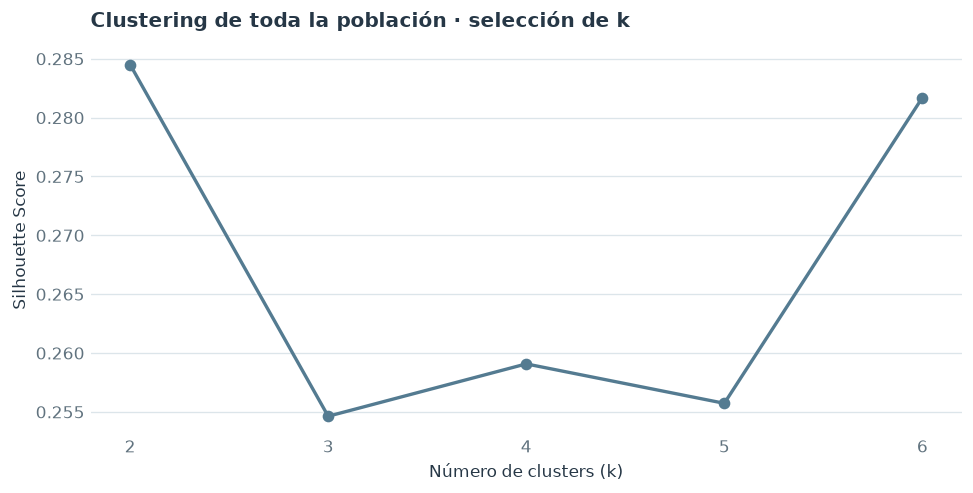

In [41]:

resultados_poblacion = []

for k in range(2, 7):
    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    etiquetas = modelo.fit_predict(X_poblacion)

    silueta = silhouette_score(
        X_poblacion,
        etiquetas,
        sample_size=2000,
        random_state=42
    )

    resultados_poblacion.append({
        "k": k,
        "silhouette": silueta,
        "inercia": modelo.inertia_
    })

resultados_poblacion = pd.DataFrame(
    resultados_poblacion
)

display(resultados_poblacion.round(3))

fig, ax = plt.subplots(
    figsize=(8, 4),
    layout="constrained"
)

preparar_eje(ax)

ax.plot(
    resultados_poblacion["k"],
    resultados_poblacion["silhouette"],
    marker="o",
    linewidth=2,
    color=COLOR["referencia"]
)

ax.set_xticks(resultados_poblacion["k"])
ax.set_xlabel("Número de clusters (k)")
ax.set_ylabel("Silhouette Score")
ax.set_title(
    "Clustering de toda la población · selección de k",
    loc="left",
    pad=12
)

plt.show()


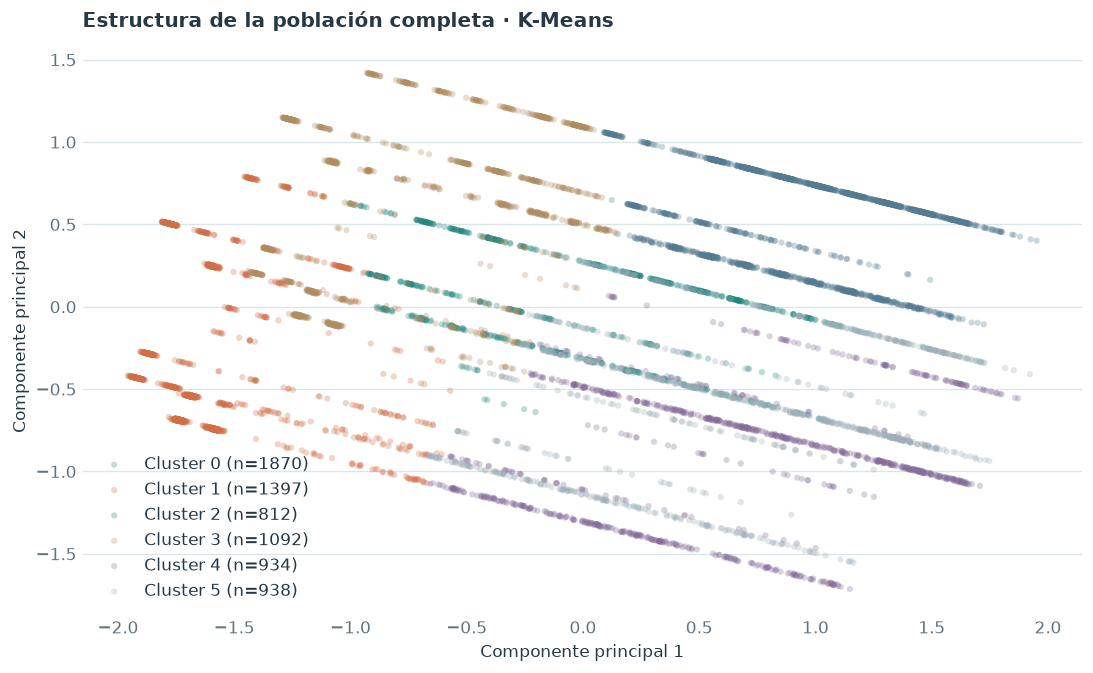

Clusters seleccionados: 6
Varianza representada por PCA: 58.1 %


In [45]:

# Seleccionar k según Silhouette Score
k_poblacion =6

modelo_poblacion = KMeans(
    n_clusters=k_poblacion,
    random_state=42,
    n_init=20
)

poblacion_cluster["cluster"] = (
    modelo_poblacion.fit_predict(X_poblacion)
)

# Proyección a dos dimensiones para visualización
pca = PCA(n_components=2)

coordenadas = pca.fit_transform(X_poblacion)

poblacion_cluster["PCA1"] = coordenadas[:, 0]
poblacion_cluster["PCA2"] = coordenadas[:, 1]

colores = [
    "#547B91",
    "#D16E46",
    "#23877F",
    "#B08C61",
    "#846C98",
    "#9DAEB8"
]

fig, ax = plt.subplots(
    figsize=(9, 5.5),
    layout="constrained"
)

preparar_eje(ax)

for cluster in sorted(
    poblacion_cluster["cluster"].unique()
):
    grupo = poblacion_cluster.loc[
        poblacion_cluster["cluster"] == cluster
    ]

    ax.scatter(
        grupo["PCA1"],
        grupo["PCA2"],
        color=colores[cluster],
        alpha=0.30,
        s=14,
        edgecolors="none",
        label=f"Cluster {cluster} (n={len(grupo)})"
    )

ax.set_title(
    "Estructura de la población completa · K-Means",
    loc="left",
    pad=12
)

ax.set_xlabel("Componente principal 1")
ax.set_ylabel("Componente principal 2")
ax.legend(frameon=False)

plt.show()

print("Clusters seleccionados:", k_poblacion)

print(
    "Varianza representada por PCA:",
    round(pca.explained_variance_ratio_.sum() * 100, 1),
    "%"
)


,clientes,bajas,cargo_mensual_mediano,tasa_churn
cluster,,,,
0,1870,999,85.20,53.42
1,1397,128,20.40,9.16
2,812,295,71.12,36.33
3,1092,264,34.67,24.18
4,934,39,88.90,4.18
5,938,144,88.40,15.35


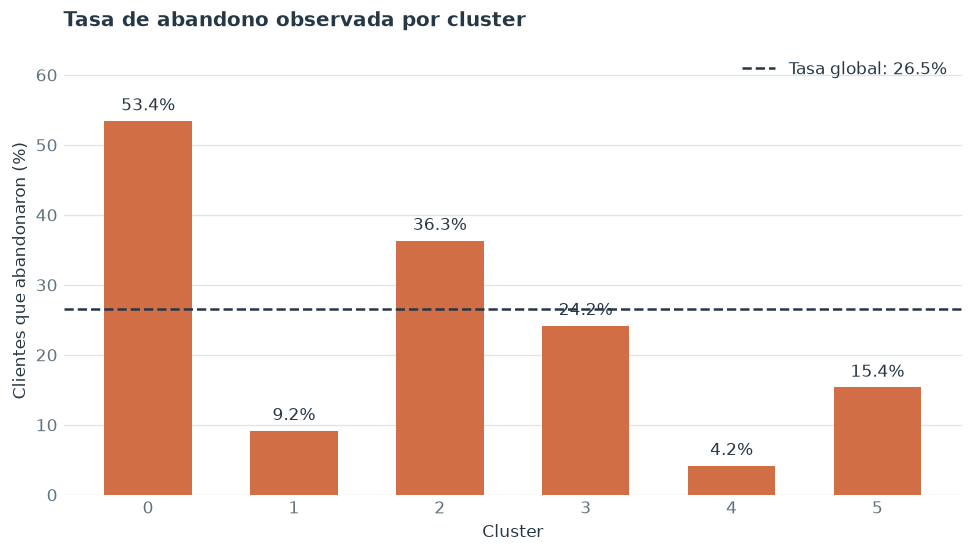

In [46]:

# Churn se utiliza SOLO después del clustering
poblacion_cluster["Churn"] = BAJA_OBSERVADA

resumen_poblacion = (
    poblacion_cluster
    .groupby("cluster")
    .agg(
        clientes=("customerID", "size"),
        bajas=("Churn", "sum"),
        cargo_mensual_mediano=("MonthlyCharges", "median")
    )
)

resumen_poblacion["tasa_churn"] = (
    100
    * resumen_poblacion["bajas"]
    / resumen_poblacion["clientes"]
)

display(resumen_poblacion.round(2))

# Comparación con la tasa global
tasa_global = BAJA_OBSERVADA.mean() * 100

fig, ax = plt.subplots(
    figsize=(8, 4.5),
    layout="constrained"
)

preparar_eje(ax)

barras = ax.bar(
    resumen_poblacion.index.astype(str),
    resumen_poblacion["tasa_churn"],
    color=COLOR["baja"],
    width=0.60
)

ax.axhline(
    tasa_global,
    color=COLOR["tinta"],
    linestyle="--",
    linewidth=1.5,
    label=f"Tasa global: {tasa_global:.1f}%"
)

ax.bar_label(
    barras,
    fmt="%.1f%%",
    padding=4
)

ax.set_title(
    "Tasa de abandono observada por cluster",
    loc="left",
    pad=12
)

ax.set_xlabel("Cluster")
ax.set_ylabel("Clientes que abandonaron (%)")
ax.set_ylim(
    0,
    max(resumen_poblacion["tasa_churn"].max(), tasa_global) * 1.2
)

ax.legend(frameon=False)

plt.show()


In [47]:

for variable in [
    "Type",
    "PaymentMethod",
    "PaperlessBilling"
]:
    print(f"\nComposición de {variable} por cluster:")

    tabla = pd.crosstab(
        poblacion_cluster["cluster"],
        poblacion_cluster[variable],
        normalize="index"
    ).mul(100).round(1)

    display(tabla)



Composición de Type por cluster:


Type,Month-to-month,One year,Two year
cluster,,,
0,100.0,0.0,0.0
1,35.0,25.7,39.3
2,98.5,0.9,0.6
3,65.6,15.5,19.0
4,0.0,0.0,100.0
5,0.0,100.0,0.0



Composición de PaymentMethod por cluster:


PaymentMethod,Bank transfer (automatic),Credit card (automatic),Electronic check,Mailed check
cluster,,,,
0,14.9,14.3,62.4,8.4
1,20.2,21.0,7.7,51.2
2,17.7,13.3,50.1,18.8
3,19.6,19.7,24.5,36.2
4,37.9,38.4,14.1,9.5
5,28.9,29.9,30.3,11.0



Composición de PaperlessBilling por cluster:


PaperlessBilling,No,Yes
cluster,,
0,0.0,100.0
1,100.0,0.0
2,100.0,0.0
3,0.0,100.0
4,38.1,61.9
5,32.7,67.3


In [48]:

# Tasas de Churn por combinación contractual
# Sin utilizar los clusters de K-Means.

comparacion_directa = contract[
    ["Type", "PaperlessBilling"]
].copy()

comparacion_directa["Churn"] = BAJA_OBSERVADA

resumen_directo = (
    comparacion_directa
    .groupby(["Type", "PaperlessBilling"])
    .agg(
        clientes=("Churn", "size"),
        bajas=("Churn", "sum"),
        tasa_churn=("Churn", "mean")
    )
)

resumen_directo["tasa_churn"] *= 100

display(resumen_directo.round(2))



clientes  bajas  tasa_churn
Type           PaperlessBilling                             
Month-to-month No                    1289    406       31.50
               Yes                   2586   1249       48.30
One year       No                     673     48        7.13
               Yes                    800    118       14.75
Two year       No                     910     15        1.65
               Yes                    785     33        4.20

In [49]:

# Comparación dentro de Month-to-month + PaperlessBilling Yes

segmento = poblacion_cluster.loc[
    (poblacion_cluster["Type"] == "Month-to-month")
    & (poblacion_cluster["PaperlessBilling"] == "Yes")
].copy()

segmento["subgrupo"] = np.where(
    segmento["cluster"] == 0,
    "Cluster 0",
    "Resto del segmento"
)

# Comparación económica y de abandono
resumen_segmento = (
    segmento.groupby("subgrupo")
    .agg(
        clientes=("customerID", "size"),
        cargo_mensual_mediano=("MonthlyCharges", "median"),
        tasa_churn=("Churn", "mean")
    )
)

resumen_segmento["tasa_churn"] *= 100

display(resumen_segmento.round(2))

# Comparación de métodos de pago
display(
    pd.crosstab(
        segmento["subgrupo"],
        segmento["PaymentMethod"],
        normalize="index"
    ).mul(100).round(1)
)


,clientes,cargo_mensual_mediano,tasa_churn
subgrupo,,,
Cluster 0,1870,85.20,53.42
Resto del segmento,716,44.45,34.92


PaymentMethod,Bank transfer (automatic),Credit card (automatic),Electronic check,Mailed check
subgrupo,,,,
Cluster 0,14.9,14.3,62.4,8.4
Resto del segmento,14.5,16.1,32.1,37.3


In [50]:

# Mismo segmento contractual:
# Month-to-month + PaperlessBilling = Yes

analisis_precio = segmento.copy()

analisis_precio["nivel_cargo"] = pd.qcut(
    analisis_precio["MonthlyCharges"],
    q=4,
    duplicates="drop"
)

resumen_precio = (
    analisis_precio
    .groupby("nivel_cargo", observed=True)
    .agg(
        clientes=("Churn", "size"),
        bajas=("Churn", "sum"),
        cargo_mediano=("MonthlyCharges", "median"),
        tasa_churn=("Churn", "mean")
    )
)

resumen_precio["tasa_churn"] *= 100

display(resumen_precio.round(2))


,clientes,bajas,cargo_mediano,tasa_churn
nivel_cargo,,,,
"(18.849, 55.0]",654,238,42.75,36.39
"(55.0, 78.55]",640,298,70.38,46.56
"(78.55, 91.4]",646,363,84.80,56.19
"(91.4, 116.5]",646,350,99.15,54.18


### H5 — Asociación entre cargo mensual y abandono dentro de un segmento contractual

**Población:** 2.586 clientes con contratos `Month-to-month` y `PaperlessBilling = Yes`.

Se dividió la población en cuatro cuartiles de `MonthlyCharges` para investigar si el nivel de facturación se relaciona con el abandono histórico.

**Resultados:**

- Q1: tasa de Churn del 36,39 %.
- Q2: tasa de Churn del 46,56 %.
- Q3: tasa de Churn del 56,19 %.
- Q4: tasa de Churn del 54,18 %.

La diferencia entre el primer y el tercer cuartil alcanza 19,80 puntos porcentuales.

**Interpretación:** se observa una asociación entre mayores cargos mensuales y mayores tasas de abandono dentro del segmento estudiado. Sin embargo, el patrón no es estrictamente creciente.

**Relación con el clustering:** los resultados sugieren que parte de la separación económica identificada por K-Means puede describirse mediante una segmentación convencional por niveles de facturación.

**Limitaciones:** la asociación no establece causalidad. No se han controlado todavía el método de pago, la antigüedad ni la composición de servicios contratados.

**Siguiente hipótesis:** investigar si los métodos de pago presentan diferencias en las tasas de abandono una vez que se considera el nivel de cargo mensual.

|